In [1]:
import re                       # expresiones regulares, para interpretar el nombre de cada registro
from pathlib import Path        # manejo de rutas de archivos

import numpy as np              # operaciones numéricas con vectores y matrices
import pandas as pd             # tablas de datos
import matplotlib.pyplot as plt # gráficos
from matplotlib.colors import TwoSlopeNorm
import wfdb                     # lectura de registros en formato WFDB (PhysioNet)

from scipy import signal

# Carpeta con el dataset. El notebook tiene que estar en la misma carpeta que "Data"
carpeta_data = Path("Data")

# Reducción de interferencias magnetohidrodinámicas en ECG adquiridos durante resonancia magnética

## 1. Carga y caracterización de los registros

Se utiliza la base de datos *Influence of the MHD effect on 12-lead and 3-lead ECGs recorded in 1T to 7T MRI scanners* (Krug Passand, 2021), publicada en PhysioNet (Goldberger et al., 2000). Contiene registros de ECG de sujetos sanos adquiridos dentro de resonadores de 1 T, 3 T y 7 T, sin secuencias de adquisición activas, por lo que la distorsión registrada corresponde principalmente al efecto magnetohidrodinámico (MHD). También incluye registros de referencia adquiridos fuera del resonador.

Los archivos están en formato **WFDB** (*WaveForm DataBase*), el formato estándar de PhysioNet para señales fisiológicas. Cada registro se compone de tres archivos:

- **`.hea` (encabezado):** archivo de texto con la frecuencia de muestreo, la cantidad de derivaciones, sus nombres, unidades y la duración del registro.
- **`.dat` (señal):** los valores muestreados de cada derivación, en formato binario.
- **`.qrs` (anotaciones):** la posición, en muestras, de cada complejo QRS, marcada manualmente por médicos o especialistas en ECG. Se utilizarán como referencia para evaluar la detección automática de latidos.

Para leerlos se utiliza la librería de Python **`wfdb`**, desarrollada por PhysioNet, que interpreta estos formatos y devuelve las señales como matrices de NumPy y las anotaciones como vectores de posiciones.

El nombre de cada registro codifica las condiciones de adquisición. Por ejemplo, `ECGMRI3T04Ff` corresponde a un campo de 3 T, sujeto 04 y posición Ff. Las posiciones son:

- **Hf** (*head first*): el sujeto ingresa al resonador con la cabeza primero.
- **Ff** (*feet first*): ingresa con los pies primero.
- **Pro** y **Sup**: decúbito prono y supino (solo en el resonador de 1 T, de campo vertical).
- **Out**: registro de referencia, fuera del resonador.

Algunos registros tienen un número final (por ejemplo, `ECGMRI3T09Ff1` a `Ff3`), que corresponde a mediciones repetidas en la misma posición.

En esta sección se leen los encabezados y las anotaciones de todos los registros, sin cargar todavía las señales completas, para construir una tabla descriptiva del conjunto.

In [2]:
# El nombre de cada registro tiene la forma ECGMRI<campo>T<sujeto><posición><repetición>.
# La expresión regular separa esas partes:
#   (\d)            -> intensidad del campo en tesla (1, 3 o 7)
#   (\d{2})         -> número de sujeto (dos dígitos)
#   (Ff|Hf|Pro|Sup|Out) -> posición
#   (\d?)           -> número de repetición (opcional)
patron_nombre = re.compile(r"ECGMRI(\d)T(\d{2})(Ff|Hf|Pro|Sup|Out)(\d?)$")

filas = []

# Se recorre cada encabezado (.hea) de la carpeta, ordenados por nombre
for archivo_hea in sorted(carpeta_data.glob("*.hea")):
    nombre = archivo_hea.stem                  # nombre del registro, sin la extensión
    ruta = str(carpeta_data / nombre)          # wfdb recibe la ruta sin extensión

    partes = patron_nombre.match(nombre)
    if partes is None:
        raise ValueError(f"Nombre de registro no reconocido: {nombre}")
    campo, sujeto, posicion, repeticion = partes.groups()

    # rdheader lee solo el encabezado (no la señal), por lo que es rápido
    encabezado = wfdb.rdheader(ruta)

    # rdann lee las anotaciones manuales de QRS (archivo .qrs)
    anotaciones = wfdb.rdann(ruta, "qrs")

    duracion_s = encabezado.sig_len / encabezado.fs

    filas.append({
        "Registro": nombre,
        "Campo (T)": int(campo),
        "Sujeto": f"{campo}T{sujeto}",          # el sujeto se identifica junto con el campo
        "Posición": posicion,
        "Repetición": repeticion or "—",
        "Dentro del resonador": posicion != "Out",
        "Frecuencia (Hz)": encabezado.fs,
        "Derivaciones": encabezado.n_sig,
        "Nombres de derivaciones": ", ".join(encabezado.sig_name),
        "Unidades": ", ".join(sorted(set(encabezado.units))),
        "Duración (s)": round(duracion_s, 1),
        "QRS anotados": len(anotaciones.sample),
        # Frecuencia cardíaca media aproximada a partir de las anotaciones
        "FC media (lpm)": round(60 * len(anotaciones.sample) / duracion_s, 1),
    })

registros = pd.DataFrame(filas)

print(f"Registros leídos: {len(registros)}")
print(f"Duración total: {registros['Duración (s)'].sum() / 60:.1f} minutos")
display(registros)

Registros leídos: 53
Duración total: 226.6 minutos


,Registro,Campo (T),Sujeto,Posición,Repetición,Dentro del resonador,Frecuencia (Hz),Derivaciones,Nombres de derivaciones,Unidades,Duración (s),QRS anotados,FC media (lpm)
0,ECGMRI1T01Out,1,1T01,Out,—,False,1024,12,"I, II, III, aVR, aVL, aVF, V1, V2, V3, V4, V5, V6",mV,29.3,44,90.1
1,ECGMRI1T01Pro,1,1T01,Pro,—,True,1024,12,"I, II, III, aVR, aVL, aVF, V1, V2, V3, V4, V5, V6",mV,39.1,57,87.6
2,ECGMRI1T01Sup,1,1T01,Sup,—,True,1024,12,"I, II, III, aVR, aVL, aVF, V1, V2, V3, V4, V5, V6",mV,26.4,38,86.5
3,ECGMRI3T01Ff,3,3T01,Ff,—,True,1024,12,"I, II, III, aVR, aVL, aVF, V1, V2, V3, V4, V5, V6",mV,326.2,361,66.4
4,ECGMRI3T01Hf,3,3T01,Hf,—,True,1024,12,"I, II, III, aVR, aVL, aVF, V1, V2, V3, V4, V5, V6",mV,366.2,400,65.5
5,ECGMRI3T01Out,3,3T01,Out,—,False,1024,12,"I, II, III, aVR, aVL, aVF, V1, V2, V3, V4, V5, V6",mV,156.2,171,65.7
6,ECGMRI3T02Ff,3,3T02,Ff,—,True,1024,12,"I, II, III, aVR, aVL, aVF, V1, V2, V3, V4, V5, V6",mV,24.4,27,66.4
7,ECGMRI3T02Out,3,3T02,Out,—,False,1024,12,"I, II, III, aVR, aVL, aVF, V1, V2, V3, V4, V5, V6",mV,24.4,27,66.4
8,ECGMRI3T03Ff,3,3T03,Ff,—,True,1024,12,"I, II, III, aVR, aVL, aVF, V1, V2, V3, V4, V5, V6",mV,195.3,186,57.1
9,ECGMRI3T03Out,3,3T03,Out,—,False,1024,12,"I, II, III, aVR, aVL, aVF, V1, V2, V3, V4, V5, V6",mV,127.0,119,56.2


In [3]:
# Cantidad de registros según el campo magnético y la posición
print("Registros por campo y posición:")
display(pd.crosstab(registros["Campo (T)"], registros["Posición"], margins=True, margins_name="Total"))

# Cantidad de registros según la cantidad de derivaciones (equipo de 3 o de 12 derivaciones)
print("Registros por cantidad de derivaciones:")
display(registros["Derivaciones"].value_counts().rename("Registros"))

# Sujetos que tienen al menos un registro dentro del resonador y uno de
# referencia fuera. Son los que permiten comparar el ECG del mismo sujeto
# con y sin efecto MHD
con_referencia = (
    registros.groupby("Sujeto")["Dentro del resonador"]
    .agg(lambda x: x.any() and (~x).any())
)
sujetos_pareados = con_referencia[con_referencia].index.tolist()

print(f"Sujetos con registro dentro y fuera del resonador: {len(sujetos_pareados)}")
print(sujetos_pareados)

Registros por campo y posición:


Posición,Ff,Hf,Out,Pro,Sup,Total
Campo (T),,,,,,
1,0,0,1,1,1,3
3,25,6,4,0,0,35
7,5,5,5,0,0,15
Total,30,11,10,1,1,53


Registros por cantidad de derivaciones:


Derivaciones
12    39
3     14
Name: Registros, dtype: int64

Sujetos con registro dentro y fuera del resonador: 10
['1T01', '3T01', '3T02', '3T03', '3T04', '7T01', '7T02', '7T03', '7T04', '7T05']


### Control de registros duplicados

En la tabla descriptiva, los registros del sujeto 7T04 presentan exactamente la misma duración, cantidad de QRS anotados y frecuencia cardíaca que los del sujeto 3T01, en las tres posiciones. Lo mismo ocurre entre los registros 3T02Ff y 3T02Out. Como es muy poco probable que dos mediciones distintas coincidan en estos tres valores, se verifica si los archivos son copias.

Para eso se calcula una huella digital (hash SHA-256) del contenido de cada archivo de señal (`.dat`) y de anotaciones (`.qrs`). El hash es un código que se obtiene a partir de todos los bytes del archivo: dos archivos con el mismo contenido producen exactamente el mismo código, y cualquier diferencia, aunque sea de un solo valor, produce un código distinto. Así se puede comprobar si dos registros son idénticos sin comparar las señales muestra por muestra.

In [4]:
import hashlib  # cálculo de huellas digitales (hash) de archivos

# Nombres de los registros (sirve tanto si la tabla tiene el nombre como
# columna como si lo tiene como índice)
nombres = (
    list(registros["Registro"]) if "Registro" in registros.columns
    else list(registros.index)
)


def huella(archivo):
    """Hash SHA-256 de todos los bytes del archivo."""
    return hashlib.sha256(archivo.read_bytes()).hexdigest()


huellas_senal = [huella(carpeta_data / f"{n}.dat") for n in nombres]
huellas_qrs = [huella(carpeta_data / f"{n}.qrs") for n in nombres]

# Agrupar los registros que comparten la misma huella
for tipo, huellas in [("señal (.dat)", huellas_senal), ("anotaciones (.qrs)", huellas_qrs)]:
    grupos = pd.Series(nombres).groupby(huellas).apply(list)
    repetidos = grupos[grupos.apply(len) > 1]

    print(f"Grupos de registros con {tipo} idénticas: {len(repetidos)}")
    for lista in repetidos:
        print("   " + " = ".join(lista))
    print()

Grupos de registros con señal (.dat) idénticas: 1
   ECGMRI3T01Out = ECGMRI7T04Out

Grupos de registros con anotaciones (.qrs) idénticas: 3
   ECGMRI3T01Hf = ECGMRI7T04Hf
   ECGMRI3T01Ff = ECGMRI7T04Ff
   ECGMRI3T01Out = ECGMRI7T04Out



El registro `ECGMRI7T04Out` es una copia exacta de `ECGMRI3T01Out`. Los registros `ECGMRI7T04Ff` y `ECGMRI7T04Hf` tienen las mismas anotaciones que `ECGMRI3T01Ff` y `ECGMRI3T01Hf`, aunque sus archivos de señal no son idénticos. Como dos sesiones distintas no pueden presentar los latidos exactamente en las mismas posiciones, se comparan las señales de cada par para determinar si corresponden a la misma grabación.

Para cada par se calcula la **correlación de Pearson** entre las señales, derivación por derivación. Mide qué tan parecida es la forma de dos señales, independientemente de su escala: vale 1 si una es copia de la otra (aunque esté multiplicada por una constante) y valores cercanos a 0 si no se parecen. También se calcula la diferencia máxima entre ambas, en mV.

In [5]:
# Pares de registros a comparar
pares = [
    ("ECGMRI3T01Ff", "ECGMRI7T04Ff"),
    ("ECGMRI3T01Hf", "ECGMRI7T04Hf"),
    ("ECGMRI3T01Out", "ECGMRI7T04Out"),
    ("ECGMRI3T02Ff", "ECGMRI3T02Out"),
]

filas_pares = []
for nombre_a, nombre_b in pares:
    # rdrecord lee la señal completa; p_signal es la matriz (muestras x derivaciones) en mV
    a = wfdb.rdrecord(str(carpeta_data / nombre_a)).p_signal
    b = wfdb.rdrecord(str(carpeta_data / nombre_b)).p_signal

    # Si tienen distinta longitud, se comparan solo las muestras en común
    n = min(len(a), len(b))
    a, b = a[:n], b[:n]

    # Correlación de cada derivación entre ambos registros
    correlaciones = [np.corrcoef(a[:, i], b[:, i])[0, 1] for i in range(a.shape[1])]

    filas_pares.append({
        "Registro A": nombre_a,
        "Registro B": nombre_b,
        "Muestras comparadas": n,
        "Correlación mínima": min(correlaciones),
        "Correlación media": np.mean(correlaciones),
        "Diferencia máxima (mV)": np.nanmax(np.abs(a - b)),
    })

display(pd.DataFrame(filas_pares).round(4))

,Registro A,Registro B,Muestras comparadas,Correlación mínima,Correlación media,Diferencia máxima (mV)
0,ECGMRI3T01Ff,ECGMRI7T04Ff,334001,0.9352,0.9485,7.7055
1,ECGMRI3T01Hf,ECGMRI7T04Hf,375001,0.9219,0.9455,17.5597
2,ECGMRI3T01Out,ECGMRI7T04Out,160000,1.0000,1.0000,0.0000
3,ECGMRI3T02Ff,ECGMRI3T02Out,25000,-0.1159,-0.0079,3.7222


In [6]:
# Registros excluidos: los tres de 7T04 duplican la sesión de 3T01
# (7T04Out es una copia exacta y 7T04Ff/7T04Hf comparten las anotaciones
# y tienen correlación > 0,92 con 3T01Ff/3T01Hf)
excluidos = ["ECGMRI7T04Ff", "ECGMRI7T04Hf", "ECGMRI7T04Out"]

registros["Excluido"] = [n in excluidos for n in nombres]
registros_validos = registros[~registros["Excluido"]].copy()

dentro = registros_validos["Dentro del resonador"]
print(f"Registros válidos: {len(registros_validos)} "
      f"({dentro.sum()} dentro y {(~dentro).sum()} fuera del resonador)")

# Comprobación con la descripción de PhysioNet (43 registros dentro, 203 minutos),
# usando la tabla completa, antes de excluir
dentro_total = registros["Dentro del resonador"]
print(f"Duración de los registros dentro del resonador (tabla completa): "
      f"{registros.loc[dentro_total, 'Duración (s)'].sum() / 60:.1f} min "
      f"en {dentro_total.sum()} registros")

print("\nRegistros válidos por campo y posición:")
display(pd.crosstab(registros_validos["Campo (T)"], registros_validos["Posición"],
                    margins=True, margins_name="Total"))

con_referencia = (
    registros_validos.groupby("Sujeto")["Dentro del resonador"]
    .agg(lambda x: x.any() and (~x).any())
)
sujetos_pareados = con_referencia[con_referencia].index.tolist()
print(f"Sujetos con registro dentro y fuera del resonador: {len(sujetos_pareados)}")
print(sujetos_pareados)

Registros válidos: 50 (41 dentro y 9 fuera del resonador)
Duración de los registros dentro del resonador (tabla completa): 203.1 min en 43 registros

Registros válidos por campo y posición:


Posición,Ff,Hf,Out,Pro,Sup,Total
Campo (T),,,,,,
1,0,0,1,1,1,3
3,25,6,4,0,0,35
7,4,4,4,0,0,12
Total,29,10,9,1,1,50


Sujetos con registro dentro y fuera del resonador: 9
['1T01', '3T01', '3T02', '3T03', '3T04', '7T01', '7T02', '7T03', '7T05']


### Resultado de la caracterización de los registros

El conjunto contiene 53 registros, todos muestreados a 1024 Hz y con las señales expresadas en mV:

- 43 registros dentro del resonador, con una duración total de 203,1 minutos, que coincide con la descripción de PhysioNet, y 10 registros de referencia fuera del resonador.
- 39 registros de 12 derivaciones (I, II, III, aVR, aVL, aVF y V1 a V6), adquiridos con el Holter CardioMem 3000, y 14 de 3 derivaciones (I, II y III), adquiridos con el monitor inalámbrico del equipo de resonancia (Tesla M3). Los de 3 derivaciones corresponden a los sujetos 3T10 a 3T23, todos en posición Ff y sin registro de referencia.
- Los registros a 1 T son cortos (26 a 39 s), mientras que los de 3 T y 7 T duran entre 24 s y 12 minutos. La frecuencia cardíaca media, estimada a partir de las anotaciones, varía entre 46 y 90 lpm.

**Registros duplicados:** El control de huellas digitales mostró que `ECGMRI7T04Out` es una copia exacta de `ECGMRI3T01Out`, y que `ECGMRI7T04Ff` y `ECGMRI7T04Hf` comparten las anotaciones de `ECGMRI3T01Ff` y `ECGMRI3T01Hf`. Sus señales presentan una correlación de entre 0,92 y 0,95 con los latidos alineados muestra a muestra, lo que no es posible entre sesiones distintas (como referencia, los registros 3T02Ff y 3T02Out, que sí son sesiones distintas, tienen una correlación cercana a 0). Por lo tanto, corresponden a una misma sesión. Se excluyen los tres registros de 7T04 y se conservan los de 3T01, ya que la serie de 3 T es consecutiva (sujetos 01 a 23) y coincide con los 23 sujetos informados en el dataset. Como no es posible confirmar cuál de las dos etiquetas de campo es la correcta, esto se considera una limitación del trabajo.

Quedan 50 registros válidos y 9 sujetos con registro dentro y fuera del resonador, que se utilizarán para comparar la morfología del ECG con y sin efecto MHD. Los 50 registros, al tener anotaciones manuales de QRS, se utilizarán para evaluar la detección de latidos.

## 2. Caracterización temporal y frecuencial

Se caracterizan las señales originales, antes de aplicar filtros,
mediante media, varianza, valor RMS, autocorrelación y densidad
espectral de potencia (PSD).

### Caracterización temporal

La media describe el nivel medio del registro. La varianza cuantifica
las fluctuaciones alrededor de ese nivel y el RMS representa la
amplitud cuadrática media. Se calculan sobre cada derivación del
registro completo, conservando las unidades físicas de adquisición.

Estas medidas describen la señal observada en su conjunto: no permiten
separar la actividad cardíaca, el efecto MHD y otras fuentes de ruido.
Por lo tanto, un aumento de varianza o RMS no se interpreta por sí
solo como una medida de interferencia MHD.

La autocorrelación se calcula sobre la señal centrada y se normaliza
por su valor a retardo cero. Se utiliza para explorar la repetitividad
temporal. Una estructura periódica no implica ausencia de interferencia,
ya que el efecto MHD también está relacionado con el ciclo cardíaco.

### Estimación de la densidad espectral de potencia

La PSD se estima mediante el método de Welch, que divide la señal en
segmentos, calcula sus periodogramas modificados y los promedia para
reducir la variabilidad de la estimación espectral (Welch, 1967).

Se utiliza una ventana Hann para reducir la fuga espectral respecto
del truncamiento rectangular. Esta reducción se obtiene a costa de
ensanchar el lóbulo principal y disminuir la capacidad de distinguir
componentes frecuenciales próximas (Harris, 1978).

Se adoptan segmentos de 4 segundos con un solapamiento del 50 %.
Como antecedente aplicado al voltaje del ECG, Ishmakhametov et al.
(2026) utilizaron Welch con ventanas Hann de 2048 muestras a 512 Hz,
equivalentes a 4 segundos, y un solapamiento del 50 %, para estimar
la PSD en una evaluación de calidad de señales fisiológicas.

En nuestro caso, se conserva esa duración temporal y se adapta la
cantidad de muestras a la frecuencia de muestreo del dataset:

N_segmento = 4 s × 1024 muestras/s = 4096 muestras.

El solapamiento corresponde a 2048 muestras y el desplazamiento
entre segmentos consecutivos es de 2 segundos.

Sin relleno con ceros, la separación entre bins es:

Δf = fs / N_segmento = 1024 / 4096 = 0,25 Hz.

Esta separación no equivale a la resolución espectral efectiva,
que también depende de la ventana.

La duración de 4 segundos permite calcular varios periodogramas
incluso en los registros más cortos del conjunto. Se adopta como
configuración inicial respaldada por un antecedente de ECG,
sin considerarla una duración óptima demostrada para este dataset.

El solapamiento permite incorporar segmentos adicionales al promedio,
aunque estos no constituyen observaciones estadísticamente
independientes.

Para calcular la PSD se elimina la media de cada segmento antes
del enventanado. Este centrado se aplica únicamente a la estimación
espectral; las estadísticas temporales se calculan sobre las señales
originales. La PSD se expresa en mV²/Hz.

### Comparación entre condiciones

Se mantienen los mismos parámetros de estimación en todos los
registros y derivaciones.

Las comparaciones dentro–fuera se realizan entre registros del mismo
identificador de sujeto y con derivaciones coincidentes. Para las
figuras comparativas se utilizan tramos iniciales de igual duración,
de hasta 30 segundos, limitados por el registro más corto del par.
Este criterio es reproducible, pero requiere inspeccionar los tramos
para identificar posibles transitorios o artefactos.

Las estadísticas generales describen los registros completos.
Las tablas que acompañan a las figuras describen únicamente
los tramos representados.

Las señales temporales no están alineadas por latidos, por lo que
no se interpreta su diferencia muestra a muestra. La alineación
y el análisis morfológico se abordarán en una etapa posterior.

Las referencias externas no son simultáneas con las adquisiciones
internas. Por ello, las diferencias temporales y espectrales no se
atribuyen exclusivamente al MHD (Krug et al., 2017).

Abi-Abdallah et al. (2007) constituye un antecedente directo de
comparación temporal y espectral de ECG dentro y fuera de un
resonador mediante Welch. Ese trabajo no especifica la ventana,
la duración de los segmentos ni el solapamiento, por lo que no
se utiliza para justificar esos parámetros.


In [7]:
# Configuración de Welch:
# Hann de 4 s y 50 % de solapamiento.
VENTANA_S = 4.0
SOLAPAMIENTO = 0.50


def estadisticas_temporales(x):
    """Estadísticas descriptivas sobre la señal original."""
    x = np.asarray(x, dtype=float)

    if (x.ndim != 1 or len(x) == 0) or (not np.isfinite(x).all()):
        raise ValueError("Error en la señal: debe ser unidimensional, no vacía y finita.")

    return {
        "Media (mV)": np.mean(x),
        "Varianza (mV²)": np.var(x, ddof=0),
        "RMS (mV)": np.sqrt(np.mean(x**2)),
    }


def calcular_psd(x, fs):
    """PSD unilateral de Welch, expresada en mV²/Hz."""
    x = np.asarray(x, dtype=float)

    if x.ndim != 1 or not np.isfinite(x).all():
        raise ValueError("La señal debe ser unidimensional y finita.")

    nperseg = int(round(VENTANA_S * fs))
    noverlap = int(round(nperseg * SOLAPAMIENTO))

    if len(x) < nperseg:
        raise ValueError(
            f"Se necesitan al menos {nperseg} muestras "
            f"para una ventana de {VENTANA_S} s."
        )

    # Hann periódica, adecuada para análisis mediante DFT.
    ventana = signal.windows.hann(nperseg, sym=False)

    f, psd = signal.welch(
        x,
        fs=fs,
        window=ventana,
        nperseg=nperseg,
        noverlap=noverlap,
        nfft=nperseg,             # Sin relleno con ceros
        detrend="constant",       # Restar media antes del enventanado
        return_onesided=True,
        scaling="density",
        average="mean",
    )

    paso = nperseg - noverlap
    cantidad_segmentos = 1 + (len(x) - nperseg) // paso

    return f, psd, cantidad_segmentos


def calcular_autocorrelacion(x, fs, max_retardo_s=3.0):
    """Autocorrelación sesgada, centrada y normalizada en retardo cero."""
    x = np.asarray(x, dtype=float)

    if x.ndim != 1 or len(x) == 0 or not np.isfinite(x).all():
        raise ValueError("La señal debe ser unidimensional, no vacía y finita.")

    centrada = x - np.mean(x)
    energia = np.dot(centrada, centrada)

    n_retardos = min(
        len(x),
        int(round(max_retardo_s * fs)) + 1,
    )
    retardos = np.arange(n_retardos) / fs

    # Una señal constante no tiene autocorrelación normalizada definida.
    if energia == 0:
        return retardos, np.full(n_retardos, np.nan)

    correlacion = signal.correlate(
        centrada,
        centrada,
        mode="full",
        method="fft",
    )

    correlacion = correlacion[
        len(x) - 1:len(x) - 1 + n_retardos
    ]

    # El factor 1/N se cancela al normalizar por el retardo cero.
    normalizada = correlacion / energia

    return retardos, normalizada

In [8]:
filas_caracteristicas = []
espectros = {}

for _, fila in registros_validos.iterrows():
    nombre = fila["Registro"]
    registro = wfdb.rdrecord(str(carpeta_data / nombre))

    fs = float(registro.fs)

    if registro.p_signal is None:
        raise ValueError(f"{nombre}: no se pudieron cargar las señales físicas.")

    for canal, derivacion in enumerate(registro.sig_name):
        unidad = registro.units[canal]

        # Las etiquetas y comparaciones de este análisis utilizan mV.
        if unidad != "mV":
            raise ValueError(
                f"{nombre}, {derivacion}: unidad inesperada '{unidad}'."
            )

        x = np.asarray(registro.p_signal[:, canal], dtype=float)

        try:
            estadisticas = estadisticas_temporales(x)
            f, psd, cantidad_segmentos = calcular_psd(x, fs)
        except ValueError as error:
            raise ValueError(
                f"Error en {nombre}, derivación {derivacion}: {error}"
            ) from error

        filas_caracteristicas.append({
            "Registro": nombre,
            "Sujeto": fila["Sujeto"],
            "Campo de la serie (T)": fila["Campo (T)"],
            "Posición": fila["Posición"],
            "Dentro del resonador": fila["Dentro del resonador"],
            "Derivación": derivacion,
            "Frecuencia de muestreo (Hz)": fs,
            "Duración (s)": len(x) / fs,
            **estadisticas,
            "Segmentos Welch": cantidad_segmentos,
        })

        espectros[(nombre, derivacion)] = {
            "Frecuencia (Hz)": f,
            "PSD (mV²/Hz)": psd,
        }

caracteristicas = pd.DataFrame(filas_caracteristicas)

print(
    f"Registros caracterizados: "
    f"{caracteristicas['Registro'].nunique()}"
)
print(f"Combinaciones registro–derivación: {len(caracteristicas)}")

display(caracteristicas.round(4))

Registros caracterizados: 50
Combinaciones registro–derivación: 474


,Registro,Sujeto,Campo de la serie (T),Posición,Dentro del resonador,Derivación,Frecuencia de muestreo (Hz),Duración (s),Media (mV),Varianza (mV²),RMS (mV),Segmentos Welch
0,ECGMRI1T01Out,1T01,1,Out,False,I,1024.0,29.2959,-0.0933,0.0087,0.1321,13
1,ECGMRI1T01Out,1T01,1,Out,False,II,1024.0,29.2959,5.9921,0.0761,5.9985,13
2,ECGMRI1T01Out,1T01,1,Out,False,III,1024.0,29.2959,0.0848,0.0405,0.2185,13
3,ECGMRI1T01Out,1T01,1,Out,False,aVR,1024.0,29.2959,-14.9500,0.0323,14.9511,13
4,ECGMRI1T01Out,1T01,1,Out,False,aVL,1024.0,29.2959,-6.0891,0.0056,6.0895,13
...,...,...,...,...,...,...,...,...,...,...,...,...
469,ECGMRI7T05Out,7T05,7,Out,False,V2,1024.0,107.4229,0.0000,0.1342,0.3664,52
470,ECGMRI7T05Out,7T05,7,Out,False,V3,1024.0,107.4229,0.0000,0.1312,0.3622,52
471,ECGMRI7T05Out,7T05,7,Out,False,V4,1024.0,107.4229,-0.0000,0.1794,0.4236,52
472,ECGMRI7T05Out,7T05,7,Out,False,V5,1024.0,107.4229,0.0000,0.1177,0.3430,52


In [9]:
# Resumen de las estadísticas de todos los registros y derivaciones.
metricas = ["Media (mV)", "Varianza (mV²)", "RMS (mV)"]

estadisticas_globales = caracteristicas.copy()

numero_derivaciones = (
    registros_validos.set_index("Registro")["Derivaciones"]
)

estadisticas_globales["Derivaciones"] = (
    estadisticas_globales["Registro"].map(numero_derivaciones)
)

estadisticas_globales["Condición"] = np.where(
    estadisticas_globales["Dentro del resonador"],
    "Dentro",
    "Fuera",
)

grupos = estadisticas_globales.groupby(
    ["Derivaciones", "Derivación", "Condición"]
)

resumen_global = pd.concat(
    [
        grupos.size().rename("Cantidad"),
        grupos[metricas].median().add_suffix(" — Mediana"),
        grupos[metricas].quantile(0.25).add_suffix(" — Q25"),
        grupos[metricas].quantile(0.75).add_suffix(" — Q75"),
    ],
    axis=1,
).reset_index()

# Mostrar una tabla por métrica para facilitar su lectura.
for metrica in metricas:
    print(f"\nResumen de {metrica}")

    columnas = [
        "Derivaciones",
        "Derivación",
        "Condición",
        "Cantidad",
        f"{metrica} — Mediana",
        f"{metrica} — Q25",
        f"{metrica} — Q75",
    ]

    display(resumen_global[columnas].round(4))


Resumen de Media (mV)


,Derivaciones,Derivación,Condición,Cantidad,Media (mV) — Mediana,Media (mV) — Q25,Media (mV) — Q75
0,3,I,Dentro,14,-1.1593,-2.5902,2.2159
1,3,II,Dentro,14,0.0922,-3.2875,3.5185
2,3,III,Dentro,14,0.1537,-2.2869,0.9641
3,12,I,Dentro,27,0.0000,-0.0034,0.0086
4,12,I,Fuera,9,-0.0000,-0.0088,0.0000
5,12,II,Dentro,27,0.0000,-0.0000,0.0154
6,12,II,Fuera,9,-0.0000,-0.0000,-0.0000
7,12,III,Dentro,27,0.0000,-0.0002,0.0084
8,12,III,Fuera,9,0.0000,-0.0000,0.0176
9,12,V1,Dentro,27,0.0000,-0.0108,0.0075



Resumen de Varianza (mV²)


,Derivaciones,Derivación,Condición,Cantidad,Varianza (mV²) — Mediana,Varianza (mV²) — Q25,Varianza (mV²) — Q75
0,3,I,Dentro,14,0.0548,0.0393,0.1091
1,3,II,Dentro,14,0.1990,0.1430,0.3387
2,3,III,Dentro,14,0.0836,0.0536,0.1286
3,12,I,Dentro,27,0.8732,0.5749,1.9683
4,12,I,Fuera,9,0.0116,0.0087,0.0137
5,12,II,Dentro,27,0.8654,0.6325,1.5066
6,12,II,Fuera,9,0.1063,0.0761,0.1253
7,12,III,Dentro,27,1.1641,0.7145,2.5547
8,12,III,Fuera,9,0.0592,0.0405,0.0676
9,12,V1,Dentro,27,0.3551,0.2479,1.0765



Resumen de RMS (mV)


,Derivaciones,Derivación,Condición,Cantidad,RMS (mV) — Mediana,RMS (mV) — Q25,RMS (mV) — Q75
0,3,I,Dentro,14,2.6473,1.3964,6.1057
1,3,II,Dentro,14,3.6999,2.3753,4.4858
2,3,III,Dentro,14,1.5201,0.9463,3.0517
3,12,I,Dentro,27,0.9345,0.7599,1.4016
4,12,I,Fuera,9,0.1114,0.0938,0.1321
5,12,II,Dentro,27,0.9330,0.7960,1.3603
6,12,II,Fuera,9,0.3274,0.3047,0.4006
7,12,III,Dentro,27,1.0789,0.8467,1.5984
8,12,III,Fuera,9,0.2434,0.2185,0.2601
9,12,V1,Dentro,27,0.5961,0.4985,1.0372


In [10]:
claves = ["Sujeto", "Derivación", "Derivaciones"]

referencias = (
    estadisticas_globales.loc[
        ~estadisticas_globales["Dentro del resonador"],
        claves + ["Registro"] + metricas,
    ]
    .rename(columns={
        "Registro": "Registro fuera",
        **{metrica: f"{metrica} fuera" for metrica in metricas},
    })
)

internos = (
    estadisticas_globales.loc[
        estadisticas_globales["Dentro del resonador"],
        claves + ["Registro", "Posición"] + metricas,
    ]
    .rename(columns={
        "Registro": "Registro dentro",
        **{metrica: f"{metrica} dentro" for metrica in metricas},
    })
)

# Se espera una sola referencia externa por sujeto y derivación.
comparaciones_pareadas = internos.merge(
    referencias,
    on=claves,
    how="inner",
    validate="many_to_one",
)

comparaciones_pareadas["Diferencia de media (mV)"] = (
    comparaciones_pareadas["Media (mV) dentro"]
    - comparaciones_pareadas["Media (mV) fuera"]
)

for metrica, nombre in [
    ("Varianza (mV²)", "Cociente varianza dentro/fuera"),
    ("RMS (mV)", "Cociente RMS dentro/fuera"),
]:
    denominador = comparaciones_pareadas[f"{metrica} fuera"]

    comparaciones_pareadas[nombre] = (
        comparaciones_pareadas[f"{metrica} dentro"]
        / denominador.where(denominador > 0)
    )

columnas_mostrar = [
    "Registro dentro",
    "Registro fuera",
    "Derivación",
    "Diferencia de media (mV)",
    "Cociente varianza dentro/fuera",
    "Cociente RMS dentro/fuera",
]

display(
    comparaciones_pareadas[columnas_mostrar]
    .round(4)
    .reset_index(drop=True)
)

,Registro dentro,Registro fuera,Derivación,Diferencia de media (mV),Cociente varianza dentro/fuera,Cociente RMS dentro/fuera
0,ECGMRI1T01Pro,ECGMRI1T01Out,I,0.0285,46.8930,4.8720
1,ECGMRI1T01Pro,ECGMRI1T01Out,II,0.2087,14.9571,1.0489
2,ECGMRI1T01Pro,ECGMRI1T01Out,III,0.1802,15.4973,3.8253
3,ECGMRI1T01Pro,ECGMRI1T01Out,aVR,-0.1186,19.1073,1.0092
4,ECGMRI1T01Pro,ECGMRI1T01Out,aVL,-0.0763,41.8918,1.0156
...,...,...,...,...,...,...
175,ECGMRI7T05Hf,ECGMRI7T05Out,V2,0.0000,13.9179,3.7307
176,ECGMRI7T05Hf,ECGMRI7T05Out,V3,-0.0000,11.7248,3.4242
177,ECGMRI7T05Hf,ECGMRI7T05Out,V4,-0.0000,8.7936,2.9654
178,ECGMRI7T05Hf,ECGMRI7T05Out,V5,-0.0000,12.5725,3.5458


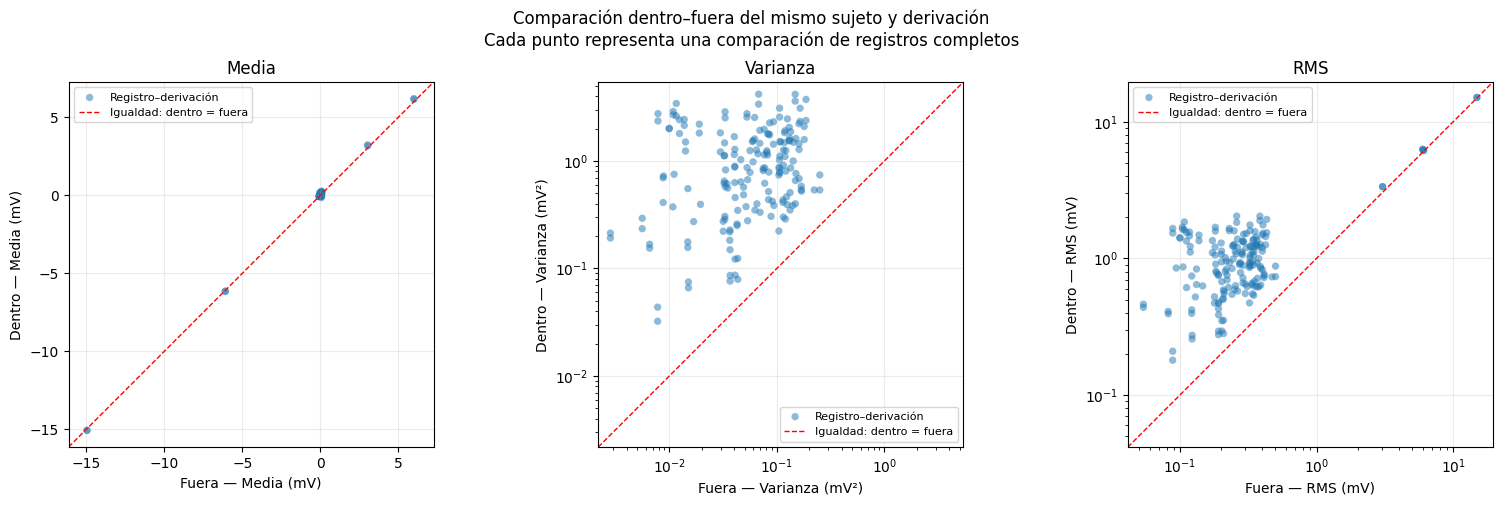

In [11]:
fig, ejes = plt.subplots(1, 3, figsize=(16, 5))

configuracion = [
    ("Media (mV)", "Media", False),
    ("Varianza (mV²)", "Varianza", True),
    ("RMS (mV)", "RMS", True),
]

for ax, (metrica, titulo, usar_log) in zip(ejes, configuracion):
    x = comparaciones_pareadas[f"{metrica} fuera"].to_numpy(dtype=float)
    y = comparaciones_pareadas[f"{metrica} dentro"].to_numpy(dtype=float)

    validos = np.isfinite(x) & np.isfinite(y)

    if usar_log:
        validos &= (x > 0) & (y > 0)

    x, y = x[validos], y[validos]

    if len(x) == 0:
        ax.set_title(titulo)
        ax.text(
            0.5, 0.5, "Sin valores disponibles",
            ha="center", transform=ax.transAxes,
        )
        continue

    ax.scatter(
        x, y,
        s=28,
        alpha=0.5,
        edgecolors="none",
        label="Registro–derivación",
    )

    valores = np.concatenate([x, y])

    if usar_log:
        minimo = valores.min() / 1.3
        maximo = valores.max() * 1.3
        ax.set_xscale("log")
        ax.set_yscale("log")
    else:
        minimo, maximo = valores.min(), valores.max()
        margen = max((maximo - minimo) * 0.05, 0.01)
        minimo -= margen
        maximo += margen

    # Igualdad y mismos límites en ambos ejes.
    ax.plot(
        [minimo, maximo],
        [minimo, maximo],
        "r--",
        linewidth=1,
        label="Igualdad: dentro = fuera",
    )

    ax.set_xlim(minimo, maximo)
    ax.set_ylim(minimo, maximo)
    ax.set_aspect("equal", adjustable="box")

    ax.set(
        title=titulo,
        xlabel=f"Fuera — {metrica}",
        ylabel=f"Dentro — {metrica}",
    )

    ax.grid(alpha=0.25)
    ax.legend(fontsize=8)

fig.suptitle(
    "Comparación dentro–fuera del mismo sujeto y derivación\n"
    "Cada punto representa una comparación de registros completos"
)

plt.tight_layout()
# plt.show()

La comparación pareada muestra medias similares dentro y fuera
del resonador, con puntos próximos a la recta de igualdad.
En cambio, todas las comparaciones presentan mayor varianza
y RMS en la adquisición interna.

El cociente de varianzas presenta una mediana de 13,88 y el
cociente de RMS una mediana de 3,45. Estos resultados indican
mayores fluctuaciones y mayor amplitud cuadrática media dentro
del resonador, sin un desplazamiento generalizado del nivel medio.

En algunas derivaciones con niveles medios elevados, el RMS
permanece próximo a la igualdad, dado que esta medida incluye
la contribución de la media: RMS² = varianza + media².
Por ello, la varianza resulta más directa para describir
las fluctuaciones alrededor del nivel medio.

Los resultados son descriptivos y corresponden a adquisiciones
no simultáneas de distinta duración. No permiten atribuir todo
el incremento exclusivamente al MHD. Las comparaciones comparten
sujetos y referencias, por lo que no son observaciones independientes.

In [12]:
def comparar_registros(
    nombre_fuera,
    nombre_dentro,
    derivacion="II",
    duracion_max_s=30.0,
):
    """Compara registros del mismo grupo, sin filtrar ni alinear latidos."""

    tabla = registros_validos.set_index("Registro")

    for nombre in (nombre_fuera, nombre_dentro):
        if nombre not in tabla.index:
            raise ValueError(
                f"{nombre} no pertenece al conjunto de registros conservados."
            )

    fila_fuera = tabla.loc[nombre_fuera]
    fila_dentro = tabla.loc[nombre_dentro]

    if bool(fila_fuera["Dentro del resonador"]):
        raise ValueError("El primer registro debe ser una referencia Out.")

    if not bool(fila_dentro["Dentro del resonador"]):
        raise ValueError("El segundo registro debe estar dentro del resonador.")

    if fila_fuera["Sujeto"] != fila_dentro["Sujeto"]:
        raise ValueError("Los registros deben pertenecer al mismo grupo.")

    if fila_fuera["Derivaciones"] != fila_dentro["Derivaciones"]:
        raise ValueError("Los registros tienen configuraciones diferentes.")

    fuera = wfdb.rdrecord(str(carpeta_data / nombre_fuera))
    dentro = wfdb.rdrecord(str(carpeta_data / nombre_dentro))

    if fuera.fs != dentro.fs:
        raise ValueError("Las frecuencias de muestreo no coinciden.")

    if (
        derivacion not in fuera.sig_name
        or derivacion not in dentro.sig_name
    ):
        raise ValueError(
            f"La derivación {derivacion} no está disponible en ambos registros."
        )

    canal_fuera = fuera.sig_name.index(derivacion)
    canal_dentro = dentro.sig_name.index(derivacion)

    if (
        fuera.units[canal_fuera] != "mV"
        or dentro.units[canal_dentro] != "mV"
    ):
        raise ValueError("Ambas señales deben estar expresadas en mV.")

    fs = float(fuera.fs)

    if not np.isfinite(duracion_max_s) or duracion_max_s < VENTANA_S:
        raise ValueError(
            f"La duración solicitada debe ser al menos {VENTANA_S} s."
        )

    n = min(
        len(fuera.p_signal),
        len(dentro.p_signal),
        int(round(duracion_max_s * fs)),
    )

    datos = {
        "Fuera": np.asarray(
            fuera.p_signal[:n, canal_fuera], dtype=float
        ),
        "Dentro": np.asarray(
            dentro.p_signal[:n, canal_dentro], dtype=float
        ),
    }

    # Validar y calcular antes de crear la figura.
    resultados = {}
    filas_resumen = []

    for condicion, x in datos.items():
        estadisticas = estadisticas_temporales(x)
        f, psd, cantidad_segmentos = calcular_psd(x, fs)
        retardos, autocorr = calcular_autocorrelacion(x, fs)

        resultados[condicion] = {
            "Señal": x,
            "Frecuencia": f,
            "PSD": psd,
            "Retardos": retardos,
            "Autocorrelación": autocorr,
        }

        filas_resumen.append({
            "Condición": condicion,
            "Duración analizada (s)": n / fs,
            **estadisticas,
            "Segmentos Welch": cantidad_segmentos,
        })

        if np.isnan(autocorr).all():
            print(
                f"Aviso: {condicion} presenta una señal constante; "
                "su autocorrelación normalizada no está definida."
            )

    colores = {"Fuera": "tab:blue", "Dentro": "tab:orange"}

    fig, ejes = plt.subplots(2, 2, figsize=(14, 8))
    tiempo = np.arange(n) / fs
    n_vista = min(n, int(round(5 * fs)))

    for condicion, resultado in resultados.items():
        color = colores[condicion]

        ejes[0, 0].plot(
            tiempo[:n_vista],
            resultado["Señal"][:n_vista],
            color=color,
            label=condicion,
            alpha=0.8,
            linewidth=1,
        )

        ejes[0, 1].plot(
            resultado["Retardos"],
            resultado["Autocorrelación"],
            color=color,
            label=condicion,
        )

        f = resultado["Frecuencia"]
        psd = resultado["PSD"]

        # Los ceros se omiten únicamente en la representación logarítmica.
        for eje, limite in ((ejes[1, 0], 100), (ejes[1, 1], 20)):
            mascara = (f <= limite) & (psd > 0)

            eje.semilogy(
                f[mascara],
                psd[mascara],
                color=color,
                label=condicion,
            )
            eje.set_xlim(0, min(limite, fs / 2))

    ejes[0, 0].set(
        title="ECG original: primeros 5 s, sin alineación por latidos",
        xlabel="Tiempo desde el inicio de cada registro (s)",
        ylabel="Amplitud (mV)",
    )

    ejes[0, 1].set(
        title="Autocorrelación normalizada del tramo completo",
        xlabel="Retardo (s)",
        ylabel="Autocorrelación",
    )

    ejes[1, 0].set(
        title="PSD de Welch: vista de 0–100 Hz",
        xlabel="Frecuencia (Hz)",
        ylabel="PSD (mV²/Hz)",
    )

    ejes[1, 1].set(
        title="PSD de Welch: detalle de 0–20 Hz",
        xlabel="Frecuencia (Hz)",
        ylabel="PSD (mV²/Hz)",
    )

    for eje in ejes.flat:
        eje.grid(alpha=0.25)
        eje.legend()

    fig.suptitle(
        f"{nombre_fuera} vs. {nombre_dentro} — derivación {derivacion}\n"
        f"Tramos iniciales de {n / fs:.2f} s; adquisiciones no simultáneas"
    )

    fig.tight_layout(rect=(0, 0, 1, 0.93))
    plt.show()

    return pd.DataFrame(filas_resumen)

Comparación dentro–fuera: serie de 3 T


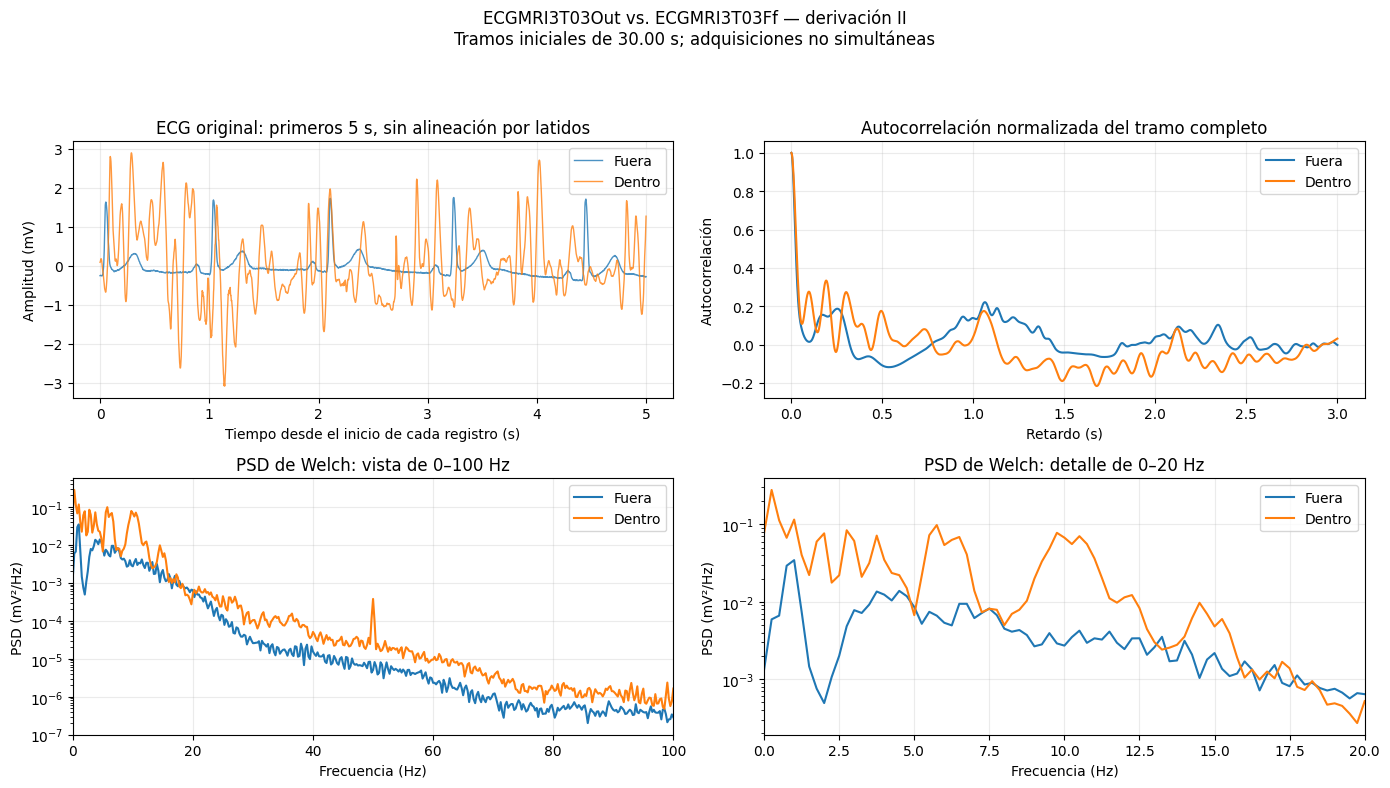

,Condición,Duración analizada (s),Media (mV),Varianza (mV²),RMS (mV),Segmentos Welch
0,Fuera,30.0,-0.0057,0.1012,0.3181,14
1,Dentro,30.0,0.0269,0.6390,0.7998,14


Comparación dentro–fuera: serie de 7 T


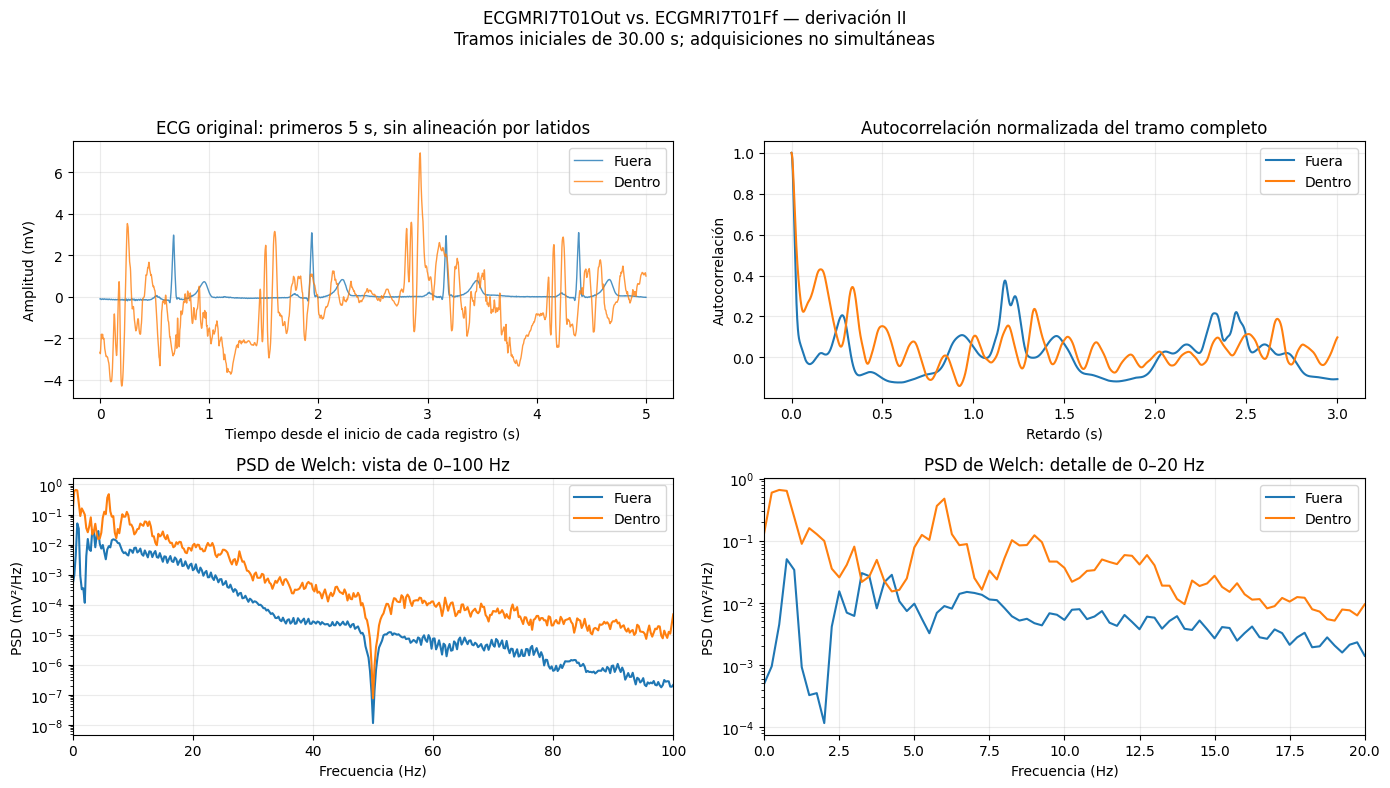

,Condición,Duración analizada (s),Media (mV),Varianza (mV²),RMS (mV),Segmentos Welch
0,Fuera,30.0,0.0467,0.1574,0.3995,14
1,Dentro,30.0,-0.0721,1.7909,1.3402,14


In [13]:
# La derivación II se utiliza como ejemplo de visualización.
# La caracterización general de la celda 2 incluye todas las derivaciones.

print("Comparación dentro–fuera: serie de 3 T")

comparacion_3t = comparar_registros(
    nombre_fuera="ECGMRI3T03Out",
    nombre_dentro="ECGMRI3T03Ff",
    derivacion="II",
)

display(comparacion_3t.round(4))


print("Comparación dentro–fuera: serie de 7 T")

comparacion_7t = comparar_registros(
    nombre_fuera="ECGMRI7T01Out",
    nombre_dentro="ECGMRI7T01Ff",
    derivacion="II",
)

display(comparacion_7t.round(4))

### Conclusión de la caracterización temporal y frecuencial

En los dos ejemplos analizados —3T03 y 7T01, derivación II—,
los registros adquiridos dentro del resonador presentan oscilaciones
de mayor amplitud y una morfología cardíaca menos claramente
reconocible que sus referencias externas.

Las autocorrelaciones conservan máximos compatibles con la repetición
de los ciclos cardíacos, pero muestran diferencias entre condiciones,
especialmente a retardos cortos. Por lo tanto, la presencia de
periodicidad no garantiza la preservación de la morfología del ECG.

En ambos pares, la PSD muestra una mayor potencia del registro
interno en amplias regiones del espectro, con diferencias destacadas
en bajas frecuencias. Estas diferencias se superponen con el contenido
frecuencial del ECG, lo que evidencia la dificultad de atenuarlas
mediante filtros convencionales sin modificar también componentes
cardíacas. El análisis espectral por sí solo no permite separar
la contribución del MHD de otras fuentes de interferencia.

También se observan comportamientos diferentes alrededor de 50 Hz:
un pico estrecho en el registro interno de 3T03 y una atenuación
marcada en ambos registros de 7T01. Esto indica que el tratamiento
de la interferencia de red debe considerar las características
de cada registro y su posible acondicionamiento previo.

Estas observaciones justifican comparar distintas estrategias
de filtrado y evaluar tanto su efecto sobre la detección de QRS
como sobre la morfología del ECG. Los resultados corresponden
a dos ejemplos y no permiten concluir que las diferencias sean
exclusivamente causadas por el MHD ni que aumenten con la intensidad
del campo, dado que se comparan sujetos distintos y adquisiciones
no simultáneas.

### Exploración del contenido espectral alrededor de 50 Hz

Para identificar picos o atenuaciones alrededor de 50 Hz, se calcula
un contraste espectral por registro y derivación:

$ C_{50} = 10 \log_{10}{(\frac{PSD media en (49–51 Hz)}{PSD media en bandas vecinas})} $ 

Como referencia local se utilizan las bandas 47–49 Hz y 51–53 Hz.
Los intervalos se implementan sin compartir bins entre bandas.

Un contraste positivo indica mayor densidad de potencia alrededor
de 50 Hz respecto de su entorno; un contraste negativo indica una
depresión relativa. Un valor próximo a cero indica niveles similares.

Las bandas son una elección exploratoria del trabajo. El indicador
no confirma por sí solo interferencia de red ni permite decidir
automáticamente la aplicación de un filtro notch.

Los resultados se representan mediante un mapa de calor por registro
y derivación, y mediante boxplots separados por condición de adquisición
y número de derivaciones. Los boxplots incluyen puntos individuales.

Cada punto representa una combinación registro–derivación.
Las derivaciones de un mismo registro no son observaciones independientes;
estas figuras se utilizan con fines descriptivos.

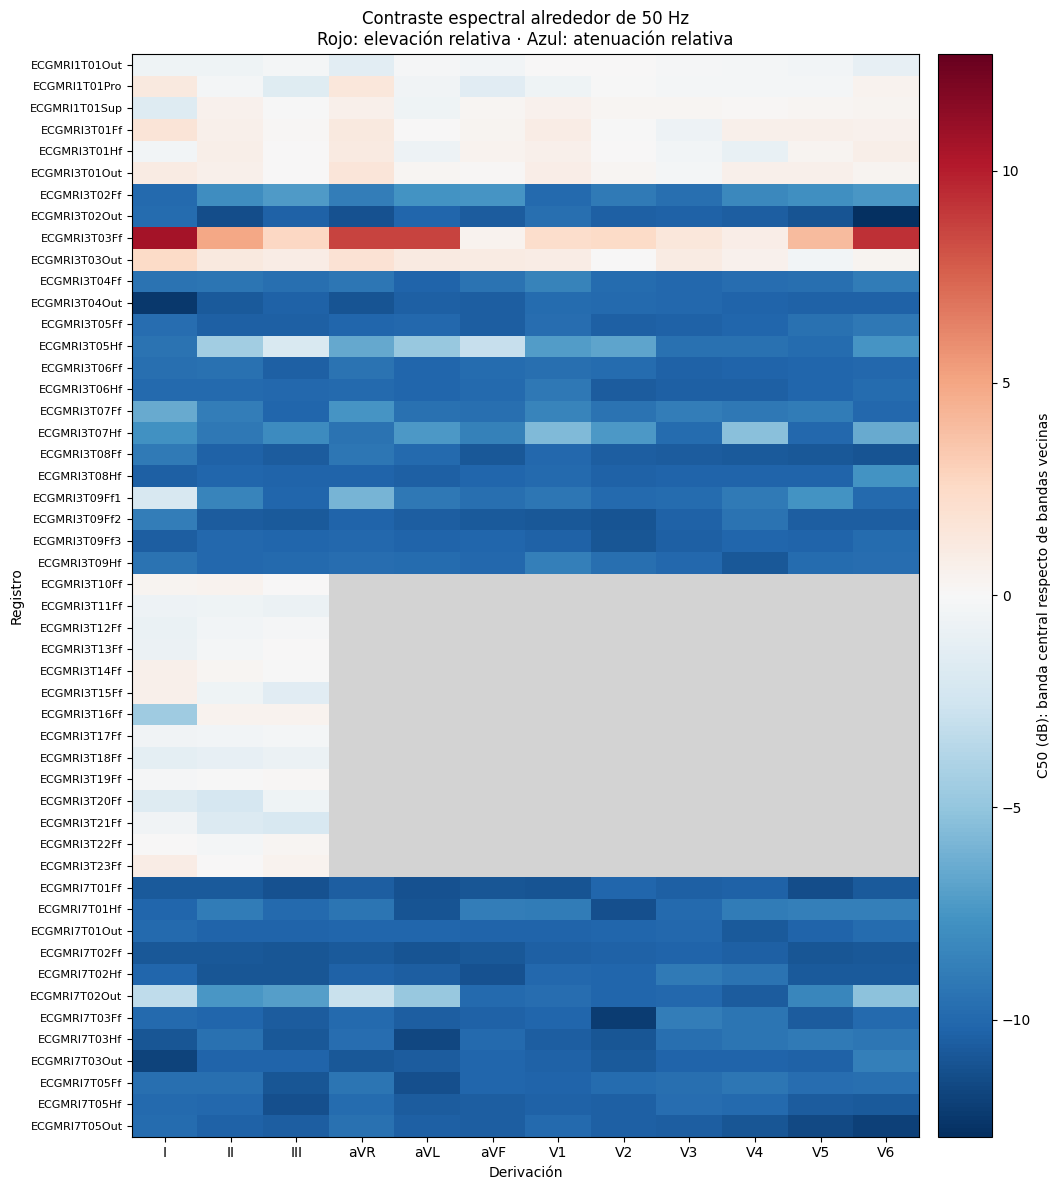

In [14]:
filas_50hz = []

for _, fila in caracteristicas.iterrows():
    nombre = fila["Registro"]
    derivacion = fila["Derivación"]

    espectro = espectros[(nombre, derivacion)]
    f = espectro["Frecuencia (Hz)"]
    psd = espectro["PSD (mV²/Hz)"]

    # Intervalos sin compartir bins:
    # central: [49, 51)
    # vecinas: [47, 49) y [51, 53)
    central = (f >= 49) & (f < 51)
    vecinas = (
        ((f >= 47) & (f < 49))
        | ((f >= 51) & (f < 53))
    )

    if not central.any() or not vecinas.any():
        raise ValueError(
            f"{nombre}, {derivacion}: faltan bins en las bandas."
        )

    media_central = np.mean(psd[central])
    media_vecinas = np.mean(psd[vecinas])

    # No se agrega una constante artificial a potencias nulas.
    if media_central > 0 and media_vecinas > 0:
        contraste = 10 * np.log10(media_central / media_vecinas)
    else:
        contraste = np.nan

    filas_50hz.append({
        "Registro": nombre,
        "Derivación": derivacion,
        "Condición": (
            "Dentro" if fila["Dentro del resonador"] else "Fuera"
        ),
        "PSD media 49–51 Hz": media_central,
        "PSD media vecinas": media_vecinas,
        "C50 (dB)": contraste,
    })

analisis_50hz = pd.DataFrame(filas_50hz)

# Incorporar la configuración de adquisición desde el inventario.
analisis_50hz = analisis_50hz.merge(
    registros_validos[["Registro", "Derivaciones"]],
    on="Registro",
    how="left",
    validate="many_to_one",
)

orden_derivaciones = [
    "I", "II", "III", "aVR", "aVL", "aVF",
    "V1", "V2", "V3", "V4", "V5", "V6",
]

presentes = analisis_50hz["Derivación"].unique()
orden_derivaciones = [
    d for d in orden_derivaciones if d in presentes
] + sorted(set(presentes) - set(orden_derivaciones))

orden_registros = sorted(analisis_50hz["Registro"].unique())

mapa_50hz = (
    analisis_50hz.pivot(
        index="Registro",
        columns="Derivación",
        values="C50 (dB)",
    )
    .reindex(index=orden_registros, columns=orden_derivaciones)
)

valores = mapa_50hz.to_numpy(dtype=float)
finitos = valores[np.isfinite(valores)]

if len(finitos) == 0:
    raise ValueError("No hay contrastes finitos para representar.")

# Escala simétrica: cero siempre representa igualdad con el entorno.
limite = max(float(np.max(np.abs(finitos))), 1.0)
norma = TwoSlopeNorm(vmin=-limite, vcenter=0, vmax=limite)

colores = plt.get_cmap("RdBu_r").copy()
colores.set_bad("lightgray")

fig, ax = plt.subplots(
    figsize=(11, max(7, 0.24 * len(mapa_50hz)))
)

imagen = ax.imshow(
    np.ma.masked_invalid(valores),
    aspect="auto",
    cmap=colores,
    norm=norma,
    interpolation="nearest",
)

ax.set_xticks(np.arange(len(mapa_50hz.columns)))
ax.set_xticklabels(mapa_50hz.columns)

ax.set_yticks(np.arange(len(mapa_50hz.index)))
ax.set_yticklabels(mapa_50hz.index, fontsize=8)

ax.set(
    title="Contraste espectral alrededor de 50 Hz\n"
          "Rojo: elevación relativa · Azul: atenuación relativa",
    xlabel="Derivación",
    ylabel="Registro",
)

barra = fig.colorbar(imagen, ax=ax, pad=0.02)
barra.set_label("C50 (dB): banda central respecto de bandas vecinas")

plt.tight_layout()
plt.show()

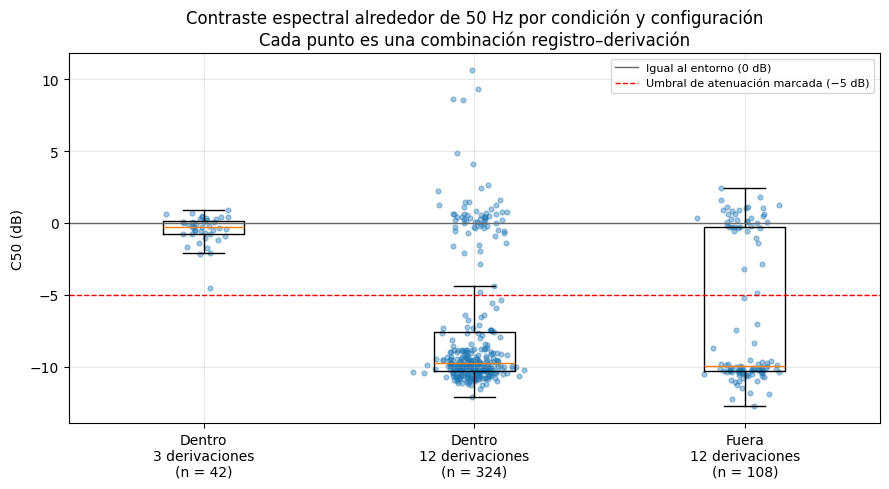

In [15]:
# Boxplots del contraste C50 por condición y configuración
grupos_c50 = (
    analisis_50hz
    .groupby(["Condición", "Derivaciones"])["C50 (dB)"]
    .apply(lambda serie: serie.dropna().to_numpy())
)

etiquetas = [
    f"{condicion}\n{derivaciones} derivaciones\n(n = {len(valores)})"
    for (condicion, derivaciones), valores in grupos_c50.items()
]

fig, ax = plt.subplots(figsize=(9, 5))

ax.boxplot(list(grupos_c50), showfliers=False)

# Puntos individuales, con un desplazamiento horizontal aleatorio
# para que no se superpongan
generador = np.random.default_rng(0)
for posicion, valores in enumerate(grupos_c50, start=1):
    ax.scatter(
        generador.normal(posicion, 0.06, len(valores)), valores,
        s=12, alpha=0.4, color="tab:blue",
    )

ax.axhline(0, color="0.4", lw=1, label="Igual al entorno (0 dB)")
# Umbral que se usa más adelante para separar los subgrupos
ax.axhline(-5, color="r", ls="--", lw=1,
           label="Umbral de atenuación marcada (−5 dB)")

ax.set_xticks(range(1, len(etiquetas) + 1))
ax.set_xticklabels(etiquetas)
ax.set(
    ylabel="C50 (dB)",
    title="Contraste espectral alrededor de 50 Hz por condición y configuración\n"
          "Cada punto es una combinación registro–derivación",
)
ax.grid(alpha=0.3)
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

### Resultado de la exploración alrededor de 50 Hz

El contraste espectral muestra un comportamiento heterogéneo entre
registros. En buena parte de las adquisiciones de 12 derivaciones
predominan valores negativos, tanto dentro como fuera del resonador,
indicando una depresión de la PSD alrededor de 50 Hz respecto de
las bandas vecinas. Este patrón es compatible con un posible
filtrado previo, aunque no permite confirmar su presencia ni su origen.

El registro ECGMRI3T03Ff se distingue por presentar valores positivos
en casi todas sus derivaciones, consistentes con el pico próximo
a 50 Hz observado en la inspección de su PSD.

En los registros de tres derivaciones, los contrastes son generalmente
cercanos a cero, indicando un nivel espectral similar al entorno.
Esto no implica ausencia de interferencia de red.

Los resultados no respaldan aplicar automáticamente un filtro notch
a todos los registros. La decisión deberá considerar la inspección
espectral y la magnitud de la componente en cada caso.

In [16]:
# Subgrupos según contraste espectral alrededor de 50 Hz

UMBRAL_C50_DB = -5.0

clasificacion_50hz = analisis_50hz.copy()

# Comprobar que todas las combinaciones puedan clasificarse.
if not np.isfinite(clasificacion_50hz["C50 (dB)"]).all():
    raise ValueError(
        "Hay valores C50 no definidos. Revisarlos antes de crear los grupos."
    )

clasificacion_50hz["Grupo 50 Hz"] = np.where(
    clasificacion_50hz["C50 (dB)"] < UMBRAL_C50_DB,
    "Atenuación marcada",
    "Resto",
)

# Tablas para utilizar en los análisis posteriores.
subgrupos_50hz = {
    "atenuacion_marcada": clasificacion_50hz.loc[
        clasificacion_50hz["Grupo 50 Hz"] == "Atenuación marcada"
    ].copy(),

    "resto": clasificacion_50hz.loc[
        clasificacion_50hz["Grupo 50 Hz"] == "Resto"
    ].copy(),
}

# Listas de pares (registro, derivación) para cargar las señales.
pares_por_grupo_50hz = {
    grupo: list(zip(tabla["Registro"], tabla["Derivación"]))
    for grupo, tabla in subgrupos_50hz.items()
}

# Resumen.
resumen_subgrupos_50hz = pd.DataFrame([
    {
        "Grupo": grupo,
        "Combinaciones registro–derivación": len(tabla),
        "Registros distintos": tabla["Registro"].nunique(),
    }
    for grupo, tabla in subgrupos_50hz.items()
])

display(resumen_subgrupos_50hz)

# Distribución por condición y configuración de adquisición.
display(pd.crosstab(
    index=[
        clasificacion_50hz["Condición"],
        clasificacion_50hz["Derivaciones"],
    ],
    columns=clasificacion_50hz["Grupo 50 Hz"],
))

,Grupo,Combinaciones registro–derivación,Registros distintos
0,atenuacion_marcada,328,28
1,resto,146,25


Grupo 50 Hz             Atenuación marcada  Resto
Condición Derivaciones                           
Dentro    3                              0     42
          12                           259     65
Fuera     12                            69     39

Se dividieron las combinaciones registro–derivación en dos grupos:
atenuación marcada (C50 < −5 dB) y resto (C50 ≥ −5 dB).

El umbral de −5 dB es un criterio operativo exploratorio del trabajo:
corresponde a una PSD media central inferior a aproximadamente el
31,6 % de la PSD media de las bandas vecinas. No confirma la existencia
de un filtro previo.

Ambos grupos se conservan para analizarlos por separado cuando
corresponda. El grupo restante puede incluir señales con elevación,
nivel similar o atenuación menos marcada alrededor de 50 Hz.

La clasificación se realiza por derivación; un mismo registro puede
contener derivaciones pertenecientes a ambos grupos.

## 3. Preprocesamiento mediante filtros convencionales

En esta sección se acondicionan las señales con filtros digitales convencionales, antes de abordar el efecto MHD. Los objetivos son:

- eliminar la deriva de la línea de base (componentes de muy baja frecuencia asociadas a la respiración y al movimiento de los electrodos);
- atenuar el ruido de alta frecuencia;
- atenuar la interferencia de red (50 Hz) donde la sección anterior detectó un pico.

El Holter CardioMem 3000, usado en los registros de 12 derivaciones, tiene un ancho de banda analógico de 0,05 a 100 Hz (Krug et al., 2013). Por lo tanto, las señales publicadas no están limitadas a una banda de monitoreo.

No se espera que esta etapa elimine el MHD. Su contenido se superpone con el de la onda T y el segmento ST (Krug y Rose, 2011), y Abi-Abdallah et al. (2007) observaron que por debajo de 5–6 Hz sigue siendo dominante. El objetivo es acondicionar la señal para las etapas siguientes y cuantificar cuánto de la diferencia dentro–fuera persiste después de un filtrado convencional.

### Elección de la banda de paso

Para fijar los cortes se analizan dos datos:

- la frecuencia cardíaca mínima del conjunto, porque el corte inferior tiene que quedar por debajo del ritmo cardíaco del registro más lento;
- la **potencia acumulada** de las señales originales: para cada frecuencia, qué porcentaje de la potencia total de la señal está por debajo de esa frecuencia (a partir de las PSD de Welch de la sección 2). Se grafica la curva típica (mediana) de cada grupo. Leyendo la curva en un corte candidato se ve directamente cuánta potencia quedaría de cada lado.

FC media mínima del conjunto: 46.5 lpm = 0.78 Hz


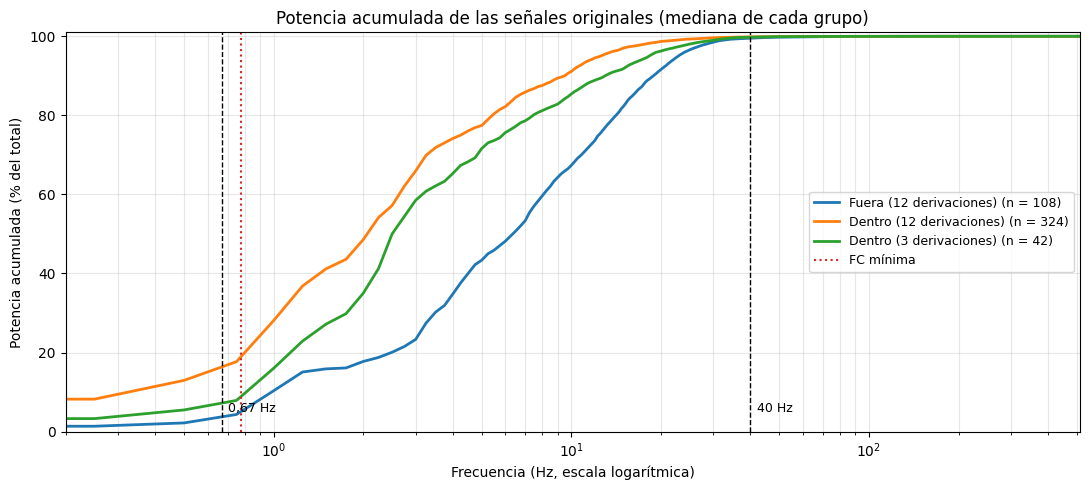

,"% de potencia por debajo de 0,67 Hz",% de potencia por debajo de 40 Hz
Grupo,,
Fuera (12 derivaciones),2.2,99.5
Dentro (12 derivaciones),13.0,99.9
Dentro (3 derivaciones),5.5,99.8


In [17]:
# Datos para elegir la banda de paso

# (a) Frecuencia cardíaca: el corte inferior tiene que quedar por debajo
# del ritmo cardíaco del registro más lento.
fc_min_lpm = registros_validos["FC media (lpm)"].min()
print(f"FC media mínima del conjunto: {fc_min_lpm:.1f} lpm = {fc_min_lpm / 60:.2f} Hz")

# (b) Potencia acumulada: para cada señal, qué porcentaje de su potencia total
# está por debajo de cada frecuencia. Se usan las PSD de Welch de la sección 2.
# Después se toma la mediana de cada grupo (curva "típica" del grupo).
CORTES_CANDIDATOS_HZ = (0.67, 40.0)

grupos_acumulada = {
    "Fuera (12 derivaciones)": [],
    "Dentro (12 derivaciones)": [],
    "Dentro (3 derivaciones)": [],
}
tabla_registros = registros_validos.set_index("Registro")

for (nombre, derivacion), espectro in espectros.items():
    psd = espectro["PSD (mV²/Hz)"]
    acumulada = 100 * np.cumsum(psd) / np.sum(psd)
    fila = tabla_registros.loc[nombre]
    condicion = "Dentro" if fila["Dentro del resonador"] else "Fuera"
    grupos_acumulada[f"{condicion} ({fila['Derivaciones']} derivaciones)"].append(acumulada)

f_acum = next(iter(espectros.values()))["Frecuencia (Hz)"]   # misma grilla para todos

fig, ax = plt.subplots(figsize=(11, 5))
filas_cortes = []

for grupo, curvas in grupos_acumulada.items():
    mediana = np.median(np.vstack(curvas), axis=0)
    ax.plot(f_acum, mediana, lw=2, label=f"{grupo} (n = {len(curvas)})")
    filas_cortes.append({
        "Grupo": grupo,
        # Último bin por debajo de cada corte (bins cada 0,25 Hz)
        **{f"% de potencia por debajo de {c:g} Hz".replace(".", ","):
               mediana[np.searchsorted(f_acum, c) - 1]
           for c in CORTES_CANDIDATOS_HZ},
    })

for corte in CORTES_CANDIDATOS_HZ:
    ax.axvline(corte, color="k", ls="--", lw=1)
    ax.text(corte * 1.05, 5, f"{corte:g} Hz".replace(".", ","), fontsize=9)
ax.axvline(fc_min_lpm / 60, color="tab:red", ls=":", lw=1.5, label="FC mínima")

ax.set(xscale="log", xlim=(0.2, 512), ylim=(0, 101),
       xlabel="Frecuencia (Hz, escala logarítmica)",
       ylabel="Potencia acumulada (% del total)",
       title="Potencia acumulada de las señales originales (mediana de cada grupo)")
ax.grid(alpha=0.3, which="both")
ax.legend(fontsize=9, loc="center right")
plt.tight_layout()
plt.show()

display(pd.DataFrame(filas_cortes).set_index("Grupo").round(1))

**Corte inferior: 0,67 Hz:** La frecuencia cardíaca media mínima del conjunto es 46,5 lpm (0,78 Hz, línea roja). Un corte en 0,67 Hz (40 lpm) queda por debajo del ritmo más lento. En la curva de las referencias externas, por debajo de 0,67 Hz está solo el 2,2 % de la potencia: la deriva existe pero es chica. Dentro del resonador ese porcentaje sube a 13 % en los registros de 12 derivaciones y a 5,5 % en los de 3 derivaciones, es decir, la deriva pesa más dentro del resonador.

**Corte superior: 40 Hz:** En las tres curvas, a 40 Hz ya se acumuló más del 99,5 % de la potencia: por encima de 40 Hz queda menos del 0,5 %. Es coherente con la bibliografía: la banda que maximiza la energía del QRS está aproximadamente entre 5 y 15 Hz (Pan y Tompkins, 1985), las ondas P y T tienen densidad espectral significativa solo hasta ~10 Hz y la mayor parte de la potencia del QRS se ubica entre 3 y 20 Hz (Abi-Abdallah et al., 2007). Además, el corte en 40 Hz deja 50 Hz fuera de la banda de paso. Como limitación, puede reducir levemente la amplitud de los picos del QRS; al aplicarse el mismo filtro dentro y fuera del resonador, la comparación entre condiciones no se ve afectada.

**Observación:** Las curvas de los registros dentro del resonador suben antes que la de las referencias externas: por ejemplo, alrededor de 5 Hz ya acumulan el 72–77 % de su potencia, contra el 43 % fuera. Dentro del resonador la potencia está corrida hacia frecuencias bajas, la misma zona que ocupan la onda T y el ST. Esto anticipa que el pasabanda no va a poder separar esa componente.

**Fase cero:** Uno de los objetivos del trabajo es evaluar la morfología del ST y de la onda T, por lo que los filtros no deben introducir distorsión de fase. La necesidad de esta condición se verifica más abajo con el retardo de grupo.

### Diseños comparados

Se diseña el mismo pasabanda de dos formas:

- **FIR por ventana de Kaiser** (`firwin`): La ventana de Kaiser permite fijar la atenuación mínima en la banda de rechazo y el ancho de la transición; `kaiserord` calcula el orden necesario (Harris, 1978). Se pide una atenuación de 40 dB y una transición de 0,5 Hz. Una transición tan angosta es necesaria porque entre el corte de 0,67 Hz y la fundamental de 0,78 Hz hay solo 0,1 Hz de margen. Por ser simétrico, el FIR tiene fase lineal.
- **IIR Butterworth** (`butter`), de orden 4, implementado en secciones de segundo orden por estabilidad numérica. Tiene la respuesta más plana en la banda de paso entre los IIR clásicos, pero su fase no es lineal.

In [18]:

# Diseño de los pasabanda FIR e IIR
FS = 1024.0                     
BANDA_PASO_HZ = (0.67, 40.0) 

# FIR: ventana de Kaiser
ATENUACION_FIR_DB = 40.0 # atenuación mínima en la banda de rechazo
TRANSICION_FIR_HZ = 0.5 # ancho de la banda de transición

# IIR: Butterworth
ORDEN_BUTTER = 4

# --- FIR ---
# kaiserord recibe el ancho de transición normalizado por la frecuencia de Nyquist
n_coef_fir, beta_kaiser = signal.kaiserord(
    ATENUACION_FIR_DB, TRANSICION_FIR_HZ / (FS / 2)
)
n_coef_fir |= 1 # longitud impar: retardo entero de (N − 1)/2 muestras

coef_fir = signal.firwin(
    n_coef_fir,
    BANDA_PASO_HZ,
    window=("kaiser", beta_kaiser),
    pass_zero=False,
    fs=FS,
)
retardo_fir = (n_coef_fir - 1) // 2

# --- IIR ---
# Secciones de segundo orden (sos): con fs = 1024 Hz, el corte de 0,67 Hz está
# muy cerca de 0 en frecuencia normalizada y la forma directa (b, a) pierde
# precisión numérica.
sos_butter = signal.butter(
    ORDEN_BUTTER, BANDA_PASO_HZ, btype="bandpass", fs=FS, output="sos"
)

# Respuestas en frecuencia
N_PUNTOS = 2**18
f_resp, h_fir = signal.freqz(coef_fir, worN=N_PUNTOS, fs=FS)
_, h_butter = signal.sosfreqz(sos_butter, worN=N_PUNTOS, fs=FS)


def a_db(h):
    return 20 * np.log10(np.maximum(np.abs(h), 1e-12))


# Magnitudes efectivas tal como se van a aplicar:
# el FIR una sola vez (compensando el retardo);
# el Butterworth hacia adelante y hacia atrás, que eleva la magnitud al cuadrado.
mag_fir_db = a_db(h_fir)
mag_butter_db = 2 * a_db(h_butter)


def valor_en(mag_db, frecuencia):
    return mag_db[np.argmin(np.abs(f_resp - frecuencia))]


frecuencias_control = {
    "0 Hz (continua)": 0.0,
    "0,3 Hz (deriva)": 0.3,
    f"{fc_min_lpm / 60:.2f} Hz (FC mínima)".replace(".", ","): fc_min_lpm / 60,
    "35 Hz": 35.0,
    "50 Hz (red)": 50.0,
}

tabla_diseno = pd.DataFrame(
    {
        "FIR Kaiser": [valor_en(mag_fir_db, f) for f in frecuencias_control.values()],
        f"Butterworth orden {ORDEN_BUTTER} (ida y vuelta)":
            [valor_en(mag_butter_db, f) for f in frecuencias_control.values()],
    },
    index=[f"Ganancia en {k} (dB)" for k in frecuencias_control],
)

print(f"FIR: {n_coef_fir} coeficientes, respuesta al impulso de {n_coef_fir / FS:.2f} s, "
      f"retardo de {retardo_fir / FS:.2f} s")
print(f"Butterworth: {sos_butter.shape[0]} secciones de 2.º orden ({sos_butter.size} coeficientes)")
display(tabla_diseno.round(2))

FIR: 4573 coeficientes, respuesta al impulso de 4.47 s, retardo de 2.23 s
Butterworth: 4 secciones de 2.º orden (24 coeficientes)


,FIR Kaiser,Butterworth orden 4 (ida y vuelta)
Ganancia en 0 Hz (continua) (dB),-42.95,-480.00
"Ganancia en 0,3 Hz (deriva) (dB)",-47.26,-56.60
"Ganancia en 0,78 Hz (FC mínima) (dB)",-2.11,-2.26
Ganancia en 35 Hz (dB),-0.00,-2.45
Ganancia en 50 Hz (red) (dB),-74.87,-17.39


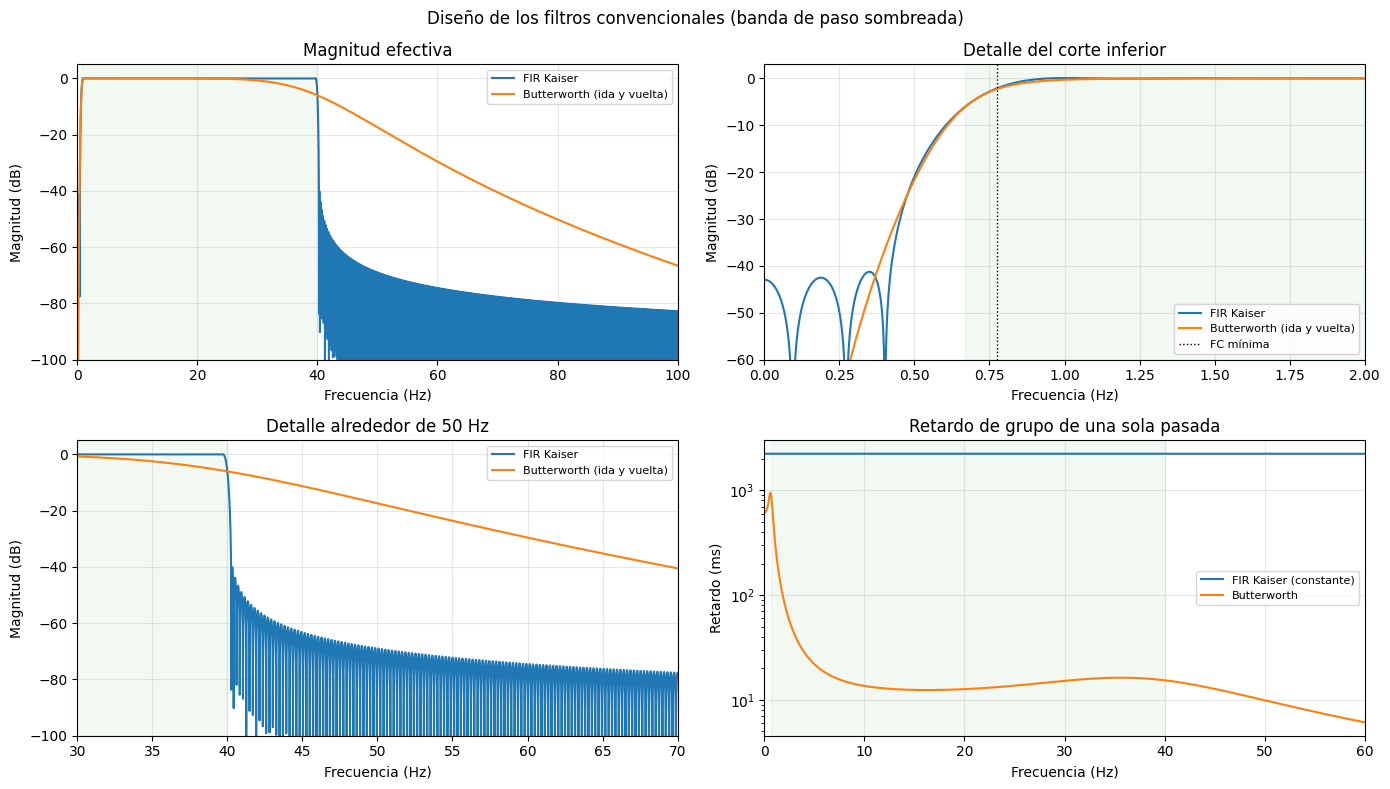

Retardo de grupo del Butterworth en 0,67–40 Hz: 12 a 863 ms
Retardo de grupo del FIR: 2232 ms en todas las frecuencias


In [19]:
# Respuestas en frecuencia y retardo de grupo
fig, ejes = plt.subplots(2, 2, figsize=(14, 8))

for ax, (xlim, ylim, titulo) in zip(
    [ejes[0, 0], ejes[0, 1], ejes[1, 0]],
    [((0, 100), (-100, 5), "Magnitud efectiva"),
     ((0, 2), (-60, 3), "Detalle del corte inferior"),
     ((30, 70), (-100, 5), "Detalle alrededor de 50 Hz")],
):
    ax.plot(f_resp, mag_fir_db, label="FIR Kaiser")
    ax.plot(f_resp, mag_butter_db, label="Butterworth (ida y vuelta)")
    ax.set(xlim=xlim, ylim=ylim, title=titulo,
           xlabel="Frecuencia (Hz)", ylabel="Magnitud (dB)")

ejes[0, 1].axvline(fc_min_lpm / 60, color="k", ls=":", lw=1, label="FC mínima")

# Retardo de grupo de UNA pasada de cada filtro
f_gd = np.linspace(0.1, 60, 2000)
_, gd_fir = signal.group_delay((coef_fir, 1.0), w=f_gd, fs=FS)

_, h_gd = signal.sosfreqz(sos_butter, worN=f_gd, fs=FS)
fase = np.unwrap(np.angle(h_gd))
gd_butter = -np.gradient(fase, 2 * np.pi * f_gd / FS)

ax = ejes[1, 1]
ax.plot(f_gd, gd_fir / FS * 1000, label="FIR Kaiser (constante)")
ax.plot(f_gd, gd_butter / FS * 1000, label="Butterworth")
ax.set(xlim=(0, 60), yscale="log", title="Retardo de grupo de una sola pasada",
       xlabel="Frecuencia (Hz)", ylabel="Retardo (ms)")

for ax in ejes.flat:
    ax.axvspan(*BANDA_PASO_HZ, color="tab:green", alpha=0.06)
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8)

fig.suptitle("Diseño de los filtros convencionales (banda de paso sombreada)")
plt.tight_layout()
plt.show()

# Variación del retardo del Butterworth dentro de la banda de paso
en_banda = (f_gd >= BANDA_PASO_HZ[0]) & (f_gd <= BANDA_PASO_HZ[1])
print(f"Retardo de grupo del Butterworth en 0,67–40 Hz: "
      f"{gd_butter[en_banda].min() / FS * 1000:.0f} a {gd_butter[en_banda].max() / FS * 1000:.0f} ms")
print(f"Retardo de grupo del FIR: {retardo_fir / FS * 1000:.0f} ms en todas las frecuencias")

### Resultado del diseño

- **Costo:** El FIR necesita 4573 coeficientes (respuesta al impulso de 4,47 s); el Butterworth, 24 (4 secciones de segundo orden).
- **Banda de paso:** El FIR es plano hasta 40 Hz (0,00 dB en 35 Hz). El Butterworth empieza a atenuar antes del corte (−2,45 dB en 35 Hz) y cae en forma gradual.
- **Corte inferior:** Ambos atenúan la deriva de forma similar (−47 dB y −57 dB en 0,3 Hz) y la fundamental del ritmo más lento casi igual (−2,1 y −2,3 dB en 0,78 Hz). La diferencia aparece en 0 Hz: el Butterworth anula completamente la continua, pero el FIR la atenúa solo 43 dB. Esto puede dejar un residuo si la señal tiene un nivel de continua alto-
- **50 Hz:** El FIR atenúa 50 Hz en 75 dB; el Butterworth, solo 17 dB.
- **Fase:** El retardo de grupo del FIR es constante (2232 ms) en todas las frecuencias. El del Butterworth varía entre 12 y 863 ms dentro de la banda de paso, con los valores más altos en las frecuencias más bajas, donde está la energía de la onda T y del ST. Aplicado una sola vez, desplazaría esas componentes respecto del QRS y deformaría la morfología.

En consecuencia, se aplican con fase cero:

- **FIR**: se compensa el retardo constante desplazando la salida (N − 1)/2 muestras.
- **IIR**: se aplica hacia adelante y hacia atrás (`sosfiltfilt`), lo que anula la fase y eleva la magnitud al cuadrado. Las magnitudes de la tabla y de la figura ya incluyen este efecto. Por eso el corte efectivo de ambos filtros queda en −6 dB.

### Nivel de continua

Como el FIR no anula la continua, se revisa el valor medio de cada derivación y el residuo que dejaría a la salida.

In [20]:
# Aplicación de los pasabanda con fase cero
def filtrar_fir(x):
    """Pasabanda FIR: convolución y compensación del retardo de (N − 1)/2 muestras.

    Antes de filtrar, la señal se extiende en ambos extremos con su reflejo
    impar (igual que hace filtfilt), para reducir el transitorio de los bordes.
    """
    x = np.asarray(x, dtype=float)
    if len(x) <= retardo_fir:
        raise ValueError("La señal es más corta que el retardo del FIR.")

    inicio = 2 * x[0] - x[retardo_fir:0:-1]
    final = 2 * x[-1] - x[-2:-retardo_fir - 2:-1]
    extendida = np.concatenate([inicio, x, final])

    # mode="same" con longitud impar devuelve la salida centrada,
    # es decir, ya desplazada (N − 1)/2 muestras
    salida = signal.fftconvolve(extendida, coef_fir, mode="same")
    return salida[retardo_fir:retardo_fir + len(x)]


def filtrar_iir(x):
    """Pasabanda Butterworth hacia adelante y hacia atrás (fase cero)."""
    return signal.sosfiltfilt(sos_butter, np.asarray(x, dtype=float))

In [21]:
# Nivel de continua de los registros y residuo esperado tras el filtrado
medias = caracteristicas.merge(
    registros_validos[["Registro", "Derivaciones"]], on="Registro", validate="many_to_one"
)
medias["|Media| (mV)"] = medias["Media (mV)"].abs()

ganancia_continua = {
    "FIR": 10 ** (valor_en(mag_fir_db, 0.0) / 20),
    "IIR": 10 ** (valor_en(mag_butter_db, 0.0) / 20),
}

resumen_continua = medias.groupby("Derivaciones")["|Media| (mV)"].agg(
    Mediana="median", Máximo="max"
)
# Residuo de continua que quedaría a la salida si no se resta la media
for metodo, ganancia in ganancia_continua.items():
    resumen_continua[f"Residuo máximo con {metodo} (mV)"] = resumen_continua["Máximo"] * ganancia

print("Valor absoluto de la media por derivación (mV):")
display(resumen_continua.round(4))

# Comprobación sobre la derivación con mayor nivel de continua
peor = medias.loc[medias["|Media| (mV)"].idxmax()]
registro = wfdb.rdrecord(str(carpeta_data / peor["Registro"]))
x = registro.p_signal[:, registro.sig_name.index(peor["Derivación"])]
borde = retardo_fir

print(f"\n{peor['Registro']} — {peor['Derivación']}: media original = {np.mean(x):.2f} mV")
for etiqueta, y in [
    ("FIR sin restar la media", filtrar_fir(x)),
    ("FIR restando la media", filtrar_fir(x - np.mean(x))),
    ("IIR sin restar la media", filtrar_iir(x)),
]:
    print(f"   {etiqueta:26s} → media de la salida = {np.mean(y[borde:-borde]):+.4f} mV")

Valor absoluto de la media por derivación (mV):


,Mediana,Máximo,Residuo máximo con FIR (mV),Residuo máximo con IIR (mV)
Derivaciones,,,,
3,2.6391,28.4132,0.2024,0.0
12,0.0032,15.0686,0.1073,0.0



ECGMRI3T17Ff — II: media original = -28.41 mV
   FIR sin restar la media    → media de la salida = +0.2021 mV
   FIR restando la media      → media de la salida = -0.0003 mV
   IIR sin restar la media    → media de la salida = -0.0003 mV


Los registros de 3 derivaciones (monitor del resonador) tienen un nivel de continua típico de 2,6 mV, y algunas derivaciones de ambos equipos llegan a 15–28 mV, entre 10 y 20 veces la amplitud del QRS. Con 43 dB de atenuación en 0 Hz, el FIR dejaría hasta 0,2 mV de continua a la salida. En la derivación II de ECGMRI3T17Ff (media de −28,4 mV), la media de la salida del FIR es de +0,20 mV sin restar la media y de −0,0003 mV restándola, igual que con el Butterworth.

Se toma la decisión de que antes de filtrar se resta la media de cada derivación. Es una operación que no modifica el resto del espectro y hace equivalentes ambos diseños en 0 Hz.

### Filtro notch

Se diseña un notch IIR de segundo orden en 50 Hz (`iirnotch`) con Q = 30. Su ancho de banda, f₀/Q ≈ 1,7 Hz, coincide aproximadamente con la banda central de 49–51 Hz usada para el contraste C50 de la sección 2. Se identifican las derivaciones con un pico relativo marcado en 50 Hz con el criterio **C50 > +3 dB** (PSD central de al menos el doble que la de las bandas vecinas), y se compara el efecto del notch combinado con cada pasabanda en la derivación con mayor C50.
Esta separación es distinta de la realizada en la sección 2. Aquella identifica las derivaciones con atenuación marcada alrededor de 50 Hz (C50 < −5 dB), que no requieren notch. El grupo restante, en cambio, incluye señales con pico, con nivel similar al entorno y con atenuación leve, y solo las primeras tienen una componente de red para eliminar. Por eso, dentro de ese grupo se distingue a las derivaciones con un pico marcado (C50 > +3 dB). 

Ancho de banda del notch: 1.67 Hz

Derivaciones con C50 > +3 dB: 6
   ECGMRI3T03Ff — I  (C50 = +10.6 dB)
   ECGMRI3T03Ff — II  (C50 = +4.9 dB)
   ECGMRI3T03Ff — V5  (C50 = +4.1 dB)
   ECGMRI3T03Ff — V6  (C50 = +9.3 dB)
   ECGMRI3T03Ff — aVL  (C50 = +8.6 dB)
   ECGMRI3T03Ff — aVR  (C50 = +8.6 dB)


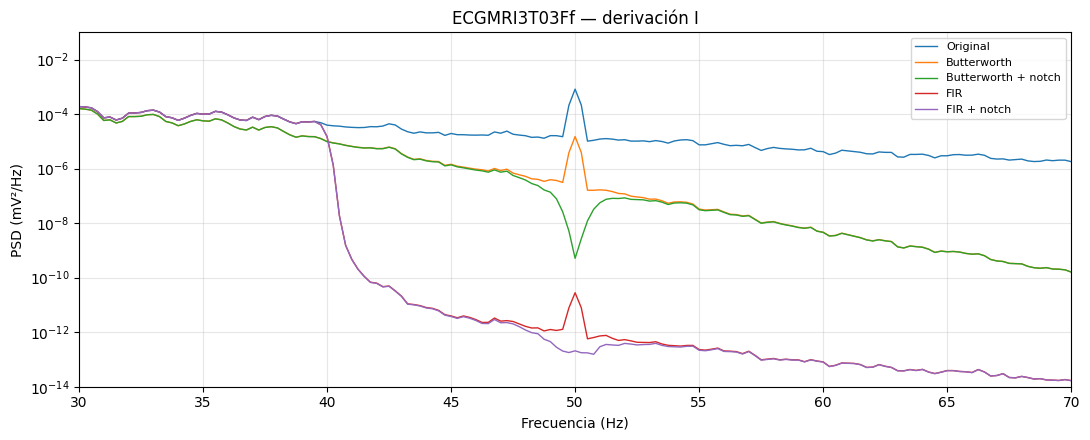

,Versión,PSD media 49–51 Hz (dB re 1 mV²/Hz),Cambio respecto del original (dB)
0,Original,-37.8,0.0
1,Butterworth,-55.2,-17.4
2,Butterworth + notch,-74.3,-36.5
3,FIR,-112.2,-74.3
4,FIR + notch,-126.4,-88.6


In [22]:
# Diseño del notch y evaluación en el registro con pico en 50 Hz
FRECUENCIA_RED_HZ = 50.0
Q_NOTCH = 30.0 # ancho de banda = f0 / Q
UMBRAL_NOTCH_C50_DB = 3.0 # pico: PSD central ≥ 2 veces la de las bandas vecinas

b_notch, a_notch = signal.iirnotch(FRECUENCIA_RED_HZ, Q_NOTCH, fs=FS)
print(f"Ancho de banda del notch: {FRECUENCIA_RED_HZ / Q_NOTCH:.2f} Hz")

# Derivaciones con pico relativo en 50 Hz, según el C50 de la sección 2
c50 = analisis_50hz.set_index(["Registro", "Derivación"])["C50 (dB)"]
derivaciones_pico_50hz = set(c50[c50 > UMBRAL_NOTCH_C50_DB].index)

print(f"\nDerivaciones con C50 > {UMBRAL_NOTCH_C50_DB:+.0f} dB: {len(derivaciones_pico_50hz)}")
for nombre, derivacion in sorted(derivaciones_pico_50hz):
    print(f"   {nombre} — {derivacion}  (C50 = {c50[(nombre, derivacion)]:+.1f} dB)")

# Evaluación en la derivación con mayor C50
nombre_notch, derivacion_notch = max(derivaciones_pico_50hz, key=lambda k: c50[k])
registro = wfdb.rdrecord(str(carpeta_data / nombre_notch))
x = registro.p_signal[:, registro.sig_name.index(derivacion_notch)]
x = x - np.mean(x)


def notch(y):
    return signal.filtfilt(b_notch, a_notch, y)


versiones = {
    "Original": x,
    "Butterworth": filtrar_iir(x),
    "Butterworth + notch": notch(filtrar_iir(x)),
    "FIR": filtrar_fir(x),
    "FIR + notch": notch(filtrar_fir(x)),
}

fig, ax = plt.subplots(figsize=(11, 4.5))
filas_notch = []
for etiqueta, y in versiones.items():
    f, psd, _ = calcular_psd(y, FS)
    ax.semilogy(f, psd, lw=1, label=etiqueta)
    filas_notch.append({
        "Versión": etiqueta,
        "PSD media 49–51 Hz (dB re 1 mV²/Hz)":
            10 * np.log10(np.mean(psd[(f >= 49) & (f < 51)])),
    })

ax.set(xlim=(30, 70), ylim=(1e-14, 1e-1),
       title=f"{nombre_notch} — derivación {derivacion_notch}",
       xlabel="Frecuencia (Hz)", ylabel="PSD (mV²/Hz)")
ax.grid(alpha=0.3, which="both")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

tabla_notch = pd.DataFrame(filas_notch)
tabla_notch["Cambio respecto del original (dB)"] = (
    tabla_notch.iloc[:, 1] - tabla_notch.iloc[0, 1]
)
display(tabla_notch.round(1))

Solo 6 derivaciones, todas de ECGMRI3T03Ff, cumplieron el criterio C50 > +3 dB. En su derivación I:

- el Butterworth reduce la PSD en 49–51 Hz en 17,4 dB, y el notch agrega otros 19 dB (−36,5 dB en total);
- el FIR solo la reduce 74,3 dB, es decir, 38 dB más que el Butterworth con notch. Agregarle el notch lleva la reducción a 88,6 dB, sobre una componente que ya estaba muy por debajo del resto del espectro.

**Decisión:** el notch solo forma parte de la cadena IIR y se aplica únicamente a las derivaciones con C50 > +3 dB. En la cadena FIR no se aplica, porque el pasabanda ya deja 50 Hz en su banda de rechazo. Las derivaciones con atenuación alrededor de 50 Hz no tienen una componente para eliminar.

### Preprocesamiento completo

Con estas decisiones, cada derivación se procesa así:

1. Remoción de la media.
2. Pasabanda de 0,67–40 Hz con fase cero (FIR o IIR).
3. Solo en la cadena IIR: notch de 50 Hz en las derivaciones con C50 > +3 dB.

In [23]:
# Preprocesamiento completo
def preprocesar(x, nombre, derivacion, metodo):
    """Preprocesamiento de una derivación.

    1. Se resta la media.
    2. Pasabanda FIR o IIR (metodo: "FIR" o "IIR"), con fase cero.
    3. Notch de 50 Hz, solo en la cadena IIR y solo en las derivaciones
       con C50 > +3 dB.
    """
    x = np.asarray(x, dtype=float)
    x = x - np.mean(x)

    if metodo == "FIR":
        return filtrar_fir(x)
    if metodo == "IIR":
        y = filtrar_iir(x)
        if (nombre, derivacion) in derivaciones_pico_50hz:
            y = signal.filtfilt(b_notch, a_notch, y)
        return y
    raise ValueError(f"Método desconocido: {metodo}")


def cargar_preprocesado(nombre, metodo):
    """Lee un registro y devuelve (fs, derivaciones, matriz muestras × derivaciones).

    Las señales filtradas no se guardan en memoria para todos los registros
    (ocuparían varios GB); se recalculan cuando se necesitan.
    """
    registro = wfdb.rdrecord(str(carpeta_data / nombre))
    matriz = np.column_stack([
        preprocesar(registro.p_signal[:, i], nombre, derivacion, metodo)
        for i, derivacion in enumerate(registro.sig_name)
    ])
    return float(registro.fs), list(registro.sig_name), matriz

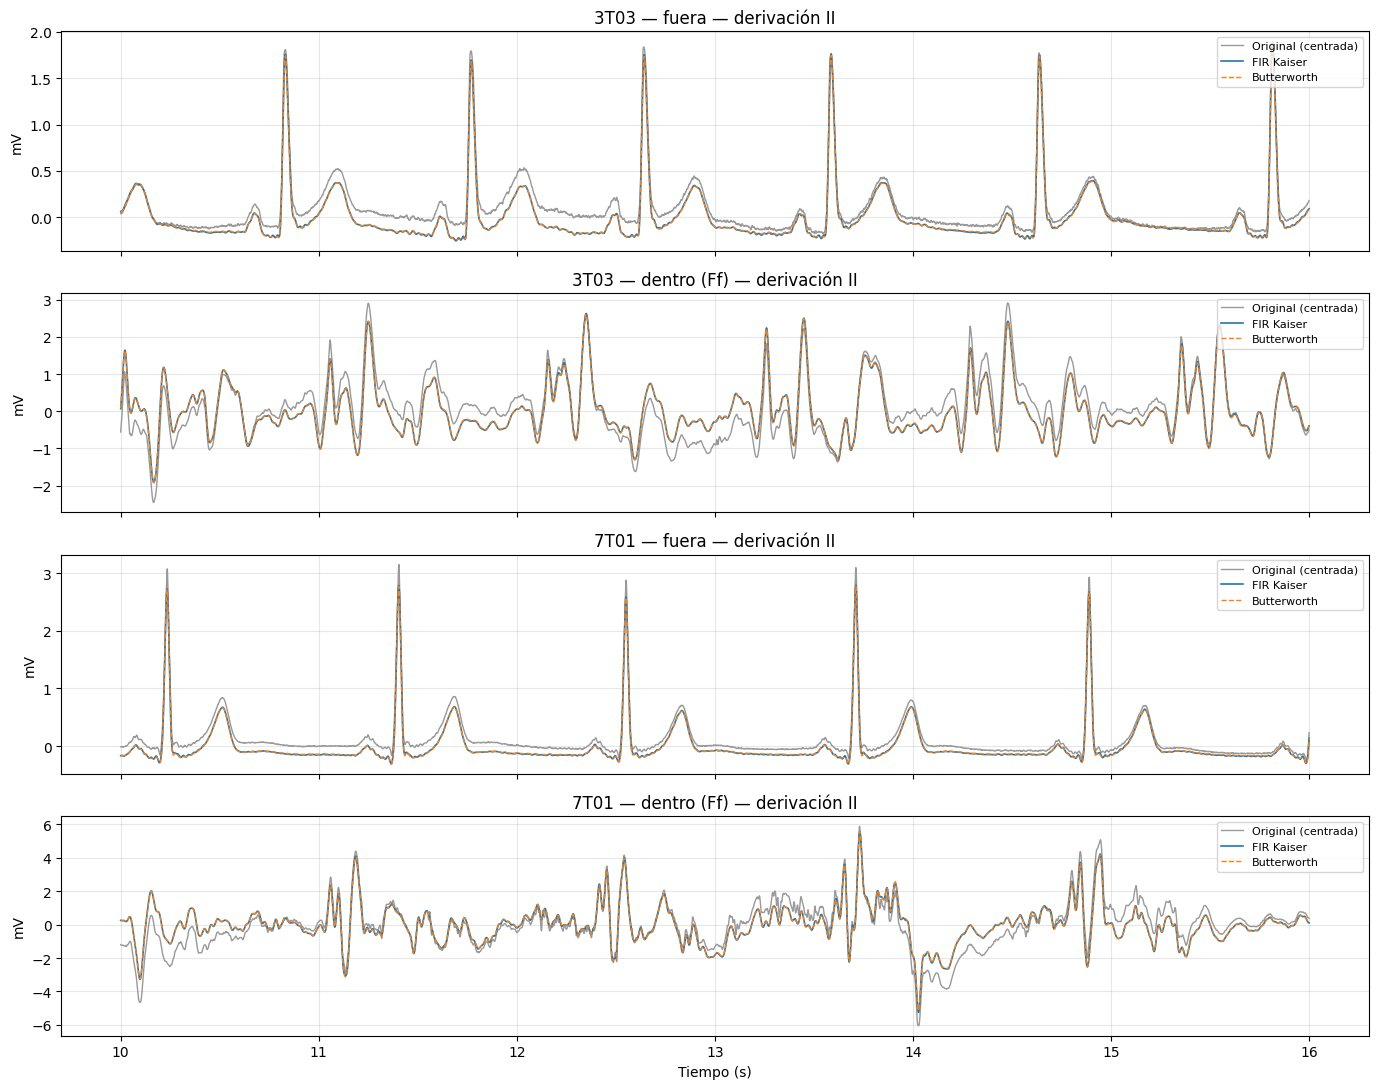

In [24]:
# Ejemplos: señal original y filtrada (3T03 y 7T01, derivación II)
DERIVACION_EJEMPLO = "II"
INICIO_S, DURACION_S = 10.0, 6.0     # tramo visualizado, lejos de los bordes

ejemplos = [
    ("ECGMRI3T03Out", "3T03 — fuera"),
    ("ECGMRI3T03Ff", "3T03 — dentro (Ff)"),
    ("ECGMRI7T01Out", "7T01 — fuera"),
    ("ECGMRI7T01Ff", "7T01 — dentro (Ff)"),
]

fig, ejes = plt.subplots(len(ejemplos), 1, figsize=(14, 11), sharex=True)

for ax, (nombre, titulo) in zip(ejes, ejemplos):
    registro = wfdb.rdrecord(str(carpeta_data / nombre))
    fs = float(registro.fs)
    canal = registro.sig_name.index(DERIVACION_EJEMPLO)
    x = registro.p_signal[:, canal]

    i0, i1 = int(INICIO_S * fs), int((INICIO_S + DURACION_S) * fs)
    t = np.arange(i0, i1) / fs

    # La señal original se centra (sin filtrar) solo para poder superponerla
    ax.plot(t, x[i0:i1] - np.median(x[i0:i1]), color="0.6", lw=1,
            label="Original (centrada)")
    ax.plot(t, preprocesar(x, nombre, DERIVACION_EJEMPLO, "FIR")[i0:i1],
            lw=1.2, label="FIR Kaiser")
    ax.plot(t, preprocesar(x, nombre, DERIVACION_EJEMPLO, "IIR")[i0:i1],
            "--", lw=1, label="Butterworth")

    ax.set(title=f"{titulo} — derivación {DERIVACION_EJEMPLO}", ylabel="mV")
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8, loc="upper right")

ejes[-1].set_xlabel("Tiempo (s)")
plt.tight_layout()
plt.show()

### Resultado de la aplicación

En las referencias externas (3T03 y 7T01 fuera), ambos filtros eliminan la deriva de la línea de base y conservan la forma del P-QRS-T. La diferencia entre FIR y Butterworth es casi imperceptible y aparece sobre todo en los picos del QRS, donde el Butterworth atenúa levemente por su caída gradual cerca de 40 Hz.

En los registros dentro del resonador, el filtrado elimina la deriva, pero la forma de onda sigue dominada por oscilaciones de baja frecuencia sincronizadas con cada latido, de amplitud comparable o mayor que la del QRS. Estas oscilaciones están dentro de la banda de paso y no pueden separarse del ECG con un filtro selectivo en frecuencia.

Para cuantificarlo sobre todo el conjunto, se calculan para cada combinación registro–derivación la varianza antes y después de filtrar, la diferencia entre las salidas de ambos diseños y la potencia de la señal filtrada en dos bandas: 0,67–10 Hz, donde se ubican la onda T, el ST y el MHD, y 10–40 Hz. Se excluyen los primeros y últimos 2,5 s de cada señal, donde están los transitorios del FIR.

In [25]:
# Efecto del preprocesamiento sobre todos los registros
BORDE_S = np.ceil(retardo_fir / FS * 2) / 2      # 2,5 s

BANDA_BAJA_HZ = (0.67, 10.0)     # donde se concentra el MHD (Krug y Rose, 2011)
BANDA_ALTA_HZ = (10.0, 40.0)


def potencia_en_banda(f, psd, banda):
    """Integral de la PSD en la banda [f1, f2), en mV²."""
    seleccion = (f >= banda[0]) & (f < banda[1])
    return np.sum(psd[seleccion]) * (f[1] - f[0])


filas_filtrado = []

for _, fila in registros_validos.iterrows():
    nombre = fila["Registro"]
    registro = wfdb.rdrecord(str(carpeta_data / nombre))
    fs = float(registro.fs)
    borde = int(BORDE_S * fs)

    for canal, derivacion in enumerate(registro.sig_name):
        x = registro.p_signal[:, canal]
        senales = {
            "Original": x,
            "FIR": preprocesar(x, nombre, derivacion, "FIR"),
            "IIR": preprocesar(x, nombre, derivacion, "IIR"),
        }
        senales = {k: v[borde:-borde] for k, v in senales.items()}

        resultado = {
            "Registro": nombre,
            "Sujeto": fila["Sujeto"],
            "Derivaciones": fila["Derivaciones"],
            "Derivación": derivacion,
            "Dentro del resonador": fila["Dentro del resonador"],
        }
        for metodo, y in senales.items():
            resultado[f"Varianza {metodo} (mV²)"] = np.var(y)

        # Diferencia entre ambos diseños, relativa a la amplitud de la señal filtrada
        resultado["Diferencia FIR–IIR relativa (%)"] = (
            100 * np.sqrt(np.mean((senales["FIR"] - senales["IIR"]) ** 2))
            / np.sqrt(np.mean(senales["FIR"] ** 2))
        )

        # Potencia por bandas de la señal filtrada con FIR
        f, psd, _ = calcular_psd(senales["FIR"], fs)
        resultado["Potencia 0,67–10 Hz (mV²)"] = potencia_en_banda(f, psd, BANDA_BAJA_HZ)
        resultado["Potencia 10–40 Hz (mV²)"] = potencia_en_banda(f, psd, BANDA_ALTA_HZ)

        filas_filtrado.append(resultado)

efecto_filtrado = pd.DataFrame(filas_filtrado)

print(f"Combinaciones registro–derivación: {len(efecto_filtrado)}")
print("\nDiferencia FIR–IIR relativa (%):")
display(efecto_filtrado["Diferencia FIR–IIR relativa (%)"]
        .describe(percentiles=[0.25, 0.5, 0.75, 0.95]).round(2))

Combinaciones registro–derivación: 474

Diferencia FIR–IIR relativa (%):


count    474.00
mean       2.59
std        1.13
min        0.58
25%        1.90
50%        2.36
75%        2.96
95%        4.85
max        9.46
Name: Diferencia FIR–IIR relativa (%), dtype: float64

Comparaciones pareadas: 180


,Cociente dentro/fuera,Mediana,Q25,Q75,Comparaciones con cociente > 1 (%)
0,Varianza — original,13.85,6.36,26.33,100.0
1,Varianza — FIR,10.77,4.78,23.66,100.0
2,Varianza — IIR,10.71,4.82,23.65,100.0
3,"Potencia 0,67–10 Hz — FIR",14.90,7.70,34.65,100.0
4,Potencia 10–40 Hz — FIR,2.65,1.36,6.94,95.0


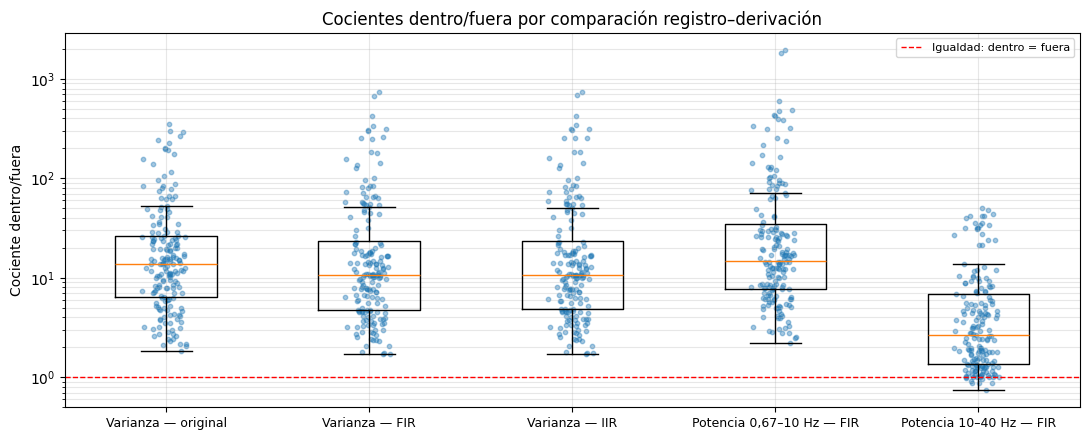

In [26]:
# Comparación pareada dentro–fuera, antes y después de filtrar
# Se repite la comparación de la sección 2 (mismo sujeto y derivación),
# ahora sobre el tramo sin bordes y para cada versión de la señal.

claves = ["Sujeto", "Derivación", "Derivaciones"]
columnas_valor = [
    "Varianza Original (mV²)", "Varianza FIR (mV²)", "Varianza IIR (mV²)",
    "Potencia 0,67–10 Hz (mV²)", "Potencia 10–40 Hz (mV²)",
]

pares_filtrado = (
    efecto_filtrado[efecto_filtrado["Dentro del resonador"]]
    [claves + ["Registro"] + columnas_valor]
    .merge(
        efecto_filtrado[~efecto_filtrado["Dentro del resonador"]]
        [claves + ["Registro"] + columnas_valor],
        on=claves, how="inner", suffixes=(" dentro", " fuera"),
        validate="many_to_one",
    )
)

cocientes = pd.DataFrame({
    "Varianza — original": "Varianza Original (mV²)",
    "Varianza — FIR": "Varianza FIR (mV²)",
    "Varianza — IIR": "Varianza IIR (mV²)",
    "Potencia 0,67–10 Hz — FIR": "Potencia 0,67–10 Hz (mV²)",
    "Potencia 10–40 Hz — FIR": "Potencia 10–40 Hz (mV²)",
}.items(), columns=["Cociente", "Columna"])

resumen_cocientes = []
valores_cocientes = {}
for _, (etiqueta, columna) in cocientes.iterrows():
    r = pares_filtrado[f"{columna} dentro"] / pares_filtrado[f"{columna} fuera"]
    valores_cocientes[etiqueta] = r
    resumen_cocientes.append({
        "Cociente dentro/fuera": etiqueta,
        "Mediana": r.median(),
        "Q25": r.quantile(0.25),
        "Q75": r.quantile(0.75),
        "Comparaciones con cociente > 1 (%)": 100 * (r > 1).mean(),
    })

print(f"Comparaciones pareadas: {len(pares_filtrado)}")
display(pd.DataFrame(resumen_cocientes).round(2))

fig, ax = plt.subplots(figsize=(11, 4.5))
ax.boxplot(list(valores_cocientes.values()), showfliers=False)
for i, r in enumerate(valores_cocientes.values(), start=1):
    ax.scatter(np.random.default_rng(0).normal(i, 0.05, len(r)), r,
               s=10, alpha=0.4, color="tab:blue")
ax.axhline(1, color="r", ls="--", lw=1, label="Igualdad: dentro = fuera")
ax.set_xticks(range(1, len(valores_cocientes) + 1))
ax.set_xticklabels(valores_cocientes.keys(), fontsize=9)
ax.set(yscale="log", ylabel="Cociente dentro/fuera",
       title="Cocientes dentro/fuera por comparación registro–derivación")
ax.grid(alpha=0.3, which="both")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

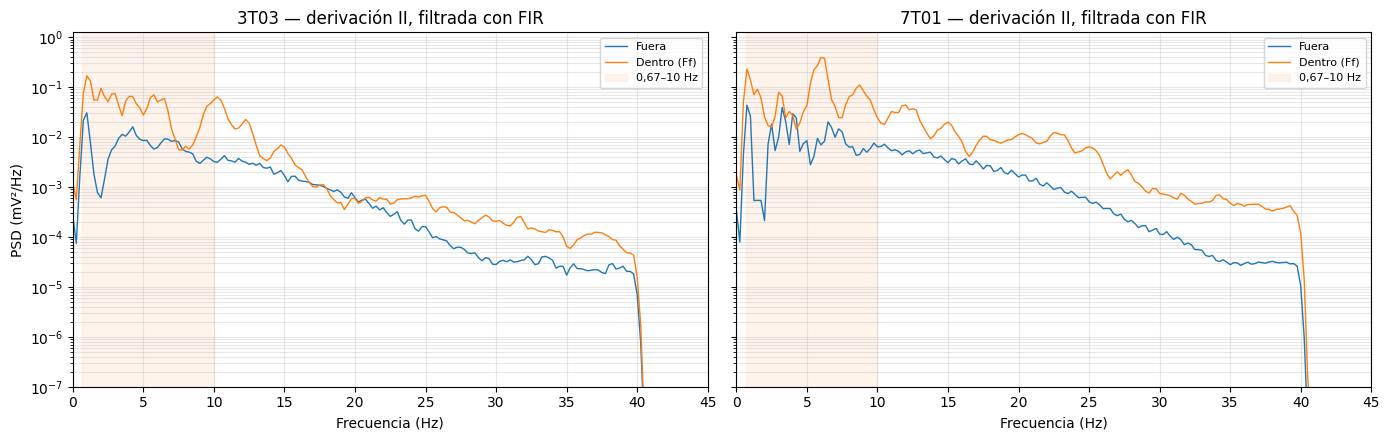

In [27]:

# PSD después de filtrar: ejemplos 3T03 y 7T01, derivación II
fig, ejes = plt.subplots(1, 2, figsize=(14, 4.5), sharey=True)

for ax, sujeto in zip(ejes, ["3T03", "7T01"]):
    for nombre, etiqueta in [(f"ECGMRI{sujeto}Out", "Fuera"),
                             (f"ECGMRI{sujeto}Ff", "Dentro (Ff)")]:
        registro = wfdb.rdrecord(str(carpeta_data / nombre))
        fs = float(registro.fs)
        borde = int(BORDE_S * fs)
        x = registro.p_signal[:, registro.sig_name.index(DERIVACION_EJEMPLO)]
        y = preprocesar(x, nombre, DERIVACION_EJEMPLO, "FIR")[borde:-borde]
        f, psd, _ = calcular_psd(y, fs)
        ax.semilogy(f, psd, lw=1, label=etiqueta)

    ax.axvspan(*BANDA_BAJA_HZ, color="tab:orange", alpha=0.08,
               label="0,67–10 Hz")
    ax.set(xlim=(0, 45), ylim=(1e-7, None),
           title=f"{sujeto} — derivación {DERIVACION_EJEMPLO}, filtrada con FIR",
           xlabel="Frecuencia (Hz)")
    ax.grid(alpha=0.3, which="both")
    ax.legend(fontsize=8)

ejes[0].set_ylabel("PSD (mV²/Hz)")
plt.tight_layout()
plt.show()

### Conclusión del preprocesamiento convencional

**Comparación de diseños:** Sobre las 474 combinaciones registro–derivación, la diferencia entre las salidas del FIR y del Butterworth tiene una mediana de 2,4 % de la amplitud RMS, atribuible principalmente a la caída gradual del Butterworth cerca de 40 Hz. Ambos diseños son prácticamente equivalentes para estas señales. **Se adopta el FIR de Kaiser como preprocesamiento para las secciones siguientes** por su banda de paso plana, su fase lineal y su rechazo de 50 Hz sin necesidad de notch. 

**El filtrado convencional no elimina el MHD:** En las 180 comparaciones pareadas dentro–fuera (mismo sujeto y derivación), la mediana del cociente de varianzas pasa de 13,9 en la señal original a 10,8 después del FIR (10,7 con el Butterworth), y en el 100 % de las comparaciones la varianza sigue siendo mayor dentro del resonador. La reducción del cociente se explica en parte por la eliminación de la deriva, que según el reparto de potencia es mayor dentro del resonador.

**El exceso de potencia se concentra en bajas frecuencias.** En la señal filtrada, el cociente de potencia dentro/fuera tiene una mediana de 14,9 en 0,67–10 Hz y de 2,7 en 10–40 Hz. Esto es coherente con lo descrito por Krug y Rose (2011) y por Abi-Abdallah et al. (2007): la distorsión MHD se ubica en la misma banda que la onda T y el segmento ST, y un filtro que la eliminara eliminaría también esas componentes del ECG. El cociente mayor que 1 en 10–40 Hz (95 % de las comparaciones) indica que dentro del resonador también hay contenido adicional en frecuencias más altas, cuyo origen no puede determinarse con este análisis.

Como en la sección anterior, los resultados son descriptivos: provienen de adquisiciones no simultáneas y de distinta duración, y las comparaciones comparten sujetos y referencias. 

## 4. Filtro de Wiener en frecuencia

La sección 3 mostró que el filtrado convencional no elimina el MHD: después del FIR, la varianza sigue siendo mayor dentro del resonador en todas las comparaciones, y el exceso de potencia se concentra en 0,67–10 Hz, la misma banda que ocupan la onda T y el segmento ST. Un filtro definido por una banda de paso no puede separar dos componentes que comparten frecuencias. Por eso el paso siguiente es un **filtro óptimo**.

### El filtro de Wiener

El filtro de Wiener plantea el filtrado como un problema de estimación. A partir de la observación u[n] (el ECG adquirido dentro del resonador) busca la salida y[n] que mejor aproxima a la señal deseada d[n] (el ECG sin MHD), minimizando el error cuadrático medio E{e²[n]}, con e[n] = d[n] − y[n]. En el dominio del tiempo, los coeficientes óptimos de un filtro FIR resultan de la ecuación de Wiener–Hopf, R_uu · b = r_ud.

Si la observación es la suma de la señal deseada y una interferencia v[n] no correlacionada con ella (u = d + v), la solución sin restricción de causalidad puede escribirse en frecuencia:

$$H(f) = \frac{S_{dd}(f)}{S_{dd}(f) + S_{vv}(f)}$$

En cada frecuencia, el filtro deja pasar la proporción de la potencia que corresponde a la señal: H ≈ 1 donde domina el ECG y H ≈ 0 donde domina la interferencia.

### Por qué en frecuencia

Krug et al. (2012) aplicaron Wiener a este mismo problema en el dominio del tiempo: resolvieron la ecuación de Wiener–Hopf con latidos adquiridos dentro del resonador, alineados en el pico R, usando como señal deseada el latido promedio del mismo sujeto fuera del resonador. Ese planteo requiere conocer la posición de cada pico R. En este punto del trabajo todavía no se detectaron los QRS, y el objetivo es justamente reducir el MHD **antes** de detectarlos. La versión en frecuencia solo necesita las densidades espectrales de potencia, que pueden estimarse sin ubicar los latidos.

### Estimación de las densidades espectrales

No se dispone del ECG sin MHD de la misma adquisición. Se usa como aproximación el registro del mismo sujeto y la misma derivación fuera del resonador:

- **S_dd(f)** ≈ PSD de la referencia externa;
- **S_vv(f)** ≈ max(S_uu(f) − S_dd(f), 0): la potencia que el registro dentro del resonador tiene en exceso respecto de la referencia.

Con estas estimaciones, H(f) = S_dd / max(S_uu, S_dd), que toma valores entre 0 y 1. Las PSD se calculan con la configuración de Welch de la sección 2, sobre las señales preprocesadas con el FIR de la sección 3 y sin los 2,5 s de cada borde.

El planteo se apoya en supuestos que hay que tener presentes al interpretar los resultados:

- que el ECG del sujeto dentro del resonador tiene el mismo espectro que fuera, aunque las adquisiciones no son simultáneas y pueden diferir en la frecuencia cardíaca y la posición;
- que el MHD no está correlacionado con el ECG, aunque lo genera el flujo de sangre de cada latido y, por lo tanto, está sincronizado con el ciclo cardíaco;
- que ambas componentes son estacionarias durante todo el registro.

### Alcance: registros con referencia externa

El método necesita, para cada registro dentro del resonador, un registro del mismo sujeto fuera del resonador. Solo 9 sujetos tienen ese registro. Los demás registros dentro del resonador (3T05–3T09, de 12 derivaciones, y 3T10–3T23, del monitor de 3 derivaciones) no tienen referencia y no pueden procesarse con este método.

**Decisión: a partir de esta sección se trabaja solo con los 9 sujetos que tienen registro dentro y fuera del resonador.** Así, este método y los que se evalúen después se comparan sobre los mismos registros, y las diferencias no se deben a un cambio en el conjunto de datos. Como contrapartida, las conclusiones de las secciones siguientes se basan en pocos sujetos por campo (1 en 1 T, 4 en 3 T y 4 en 7 T) y no son generalizables.

In [28]:
# Registros con referencia externa del mismo sujeto
registros_fuera = registros_validos[~registros_validos["Dentro del resonador"]]
registros_dentro = registros_validos[registros_validos["Dentro del resonador"]]

pares_wiener = registros_dentro.merge(
    registros_fuera[["Sujeto", "Registro", "FC media (lpm)", "Duración (s)"]],
    on="Sujeto", suffixes=("", " fuera"), validate="many_to_one",
)[["Sujeto", "Campo (T)", "Registro", "Registro fuera",
   "FC media (lpm)", "FC media (lpm) fuera", "Duración (s)", "Duración (s) fuera"]]

print(f"Sujetos con registro fuera del resonador: {pares_wiener['Sujeto'].nunique()}")
print(f"Registros dentro del resonador con referencia externa: {len(pares_wiener)}")
print(f"Registros dentro del resonador sin referencia externa: "
      f"{len(registros_dentro) - len(pares_wiener)}")
display(pares_wiener.round(1))

Sujetos con registro fuera del resonador: 9
Registros dentro del resonador con referencia externa: 15
Registros dentro del resonador sin referencia externa: 26


,Sujeto,Campo (T),Registro,Registro fuera,FC media (lpm),FC media (lpm) fuera,Duración (s),Duración (s) fuera
0,1T01,1,ECGMRI1T01Pro,ECGMRI1T01Out,87.6,90.1,39.1,29.3
1,1T01,1,ECGMRI1T01Sup,ECGMRI1T01Out,86.5,90.1,26.4,29.3
2,3T01,3,ECGMRI3T01Ff,ECGMRI3T01Out,66.4,65.7,326.2,156.2
3,3T01,3,ECGMRI3T01Hf,ECGMRI3T01Out,65.5,65.7,366.2,156.2
4,3T02,3,ECGMRI3T02Ff,ECGMRI3T02Out,66.4,66.4,24.4,24.4
5,3T03,3,ECGMRI3T03Ff,ECGMRI3T03Out,57.1,56.2,195.3,127.0
6,3T04,3,ECGMRI3T04Ff,ECGMRI3T04Out,87.0,89.6,117.2,117.2
7,7T01,7,ECGMRI7T01Ff,ECGMRI7T01Out,46.5,49.5,212.9,186.5
8,7T01,7,ECGMRI7T01Hf,ECGMRI7T01Out,47.4,49.5,286.1,186.5
9,7T02,7,ECGMRI7T02Ff,ECGMRI7T02Out,62.5,72.5,273.4,293.0


In [29]:
# Filtro de Wiener en frecuencia
def psd_sin_bordes(x, fs):
    """PSD de Welch (configuración de la sección 2) sin los bordes del FIR."""
    borde = int(BORDE_S * fs)
    f, psd, _ = calcular_psd(x[borde:-borde], fs)
    return f, psd


def ganancia_wiener(psd_dentro, psd_fuera):
    """H(f) = S_dd / (S_dd + S_vv), con S_dd ≈ PSD fuera y S_vv ≈ max(S_uu − S_dd, 0).

    Como S_dd + max(S_uu − S_dd, 0) = max(S_uu, S_dd), resulta
    H(f) = S_dd / max(S_uu, S_dd), que vale entre 0 y 1.
    """
    return psd_fuera / np.maximum(psd_dentro, psd_fuera)


def aplicar_wiener(x, fs, f_h, h):
    """Aplica H(f) multiplicando el espectro de toda la señal.

    H es real y no negativa, por lo que el filtro no modifica la fase
    (fase cero). H se interpola a la grilla de frecuencias de la FFT.
    """
    espectro = np.fft.rfft(x)
    f_fft = np.fft.rfftfreq(len(x), d=1 / fs)
    return np.fft.irfft(espectro * np.interp(f_fft, f_h, h), n=len(x))


def senal_fir(nombre, derivacion):
    """Lee una derivación y la preprocesa con el FIR de la sección 3."""
    registro = wfdb.rdrecord(str(carpeta_data / nombre))
    x = registro.p_signal[:, registro.sig_name.index(derivacion)]
    return float(registro.fs), preprocesar(x, nombre, derivacion, "FIR")


def wiener_derivacion(nombre_dentro, nombre_fuera, derivacion):
    """Diseña y aplica el Wiener para una derivación de un registro dentro del resonador.

    Devuelve un diccionario con la señal de entrada (FIR), la salida de Wiener,
    la referencia externa (FIR) y las PSD y la ganancia usadas.
    """
    fs, x_dentro = senal_fir(nombre_dentro, derivacion)
    _, x_fuera = senal_fir(nombre_fuera, derivacion)

    f, psd_dentro = psd_sin_bordes(x_dentro, fs)
    _, psd_fuera = psd_sin_bordes(x_fuera, fs)
    h = ganancia_wiener(psd_dentro, psd_fuera)

    return {
        "fs": fs, "f": f, "H": h,
        "PSD dentro": psd_dentro, "PSD fuera": psd_fuera,
        "Entrada": x_dentro,
        "Wiener": aplicar_wiener(x_dentro, fs, f, h),
        "Fuera": x_fuera,
    }

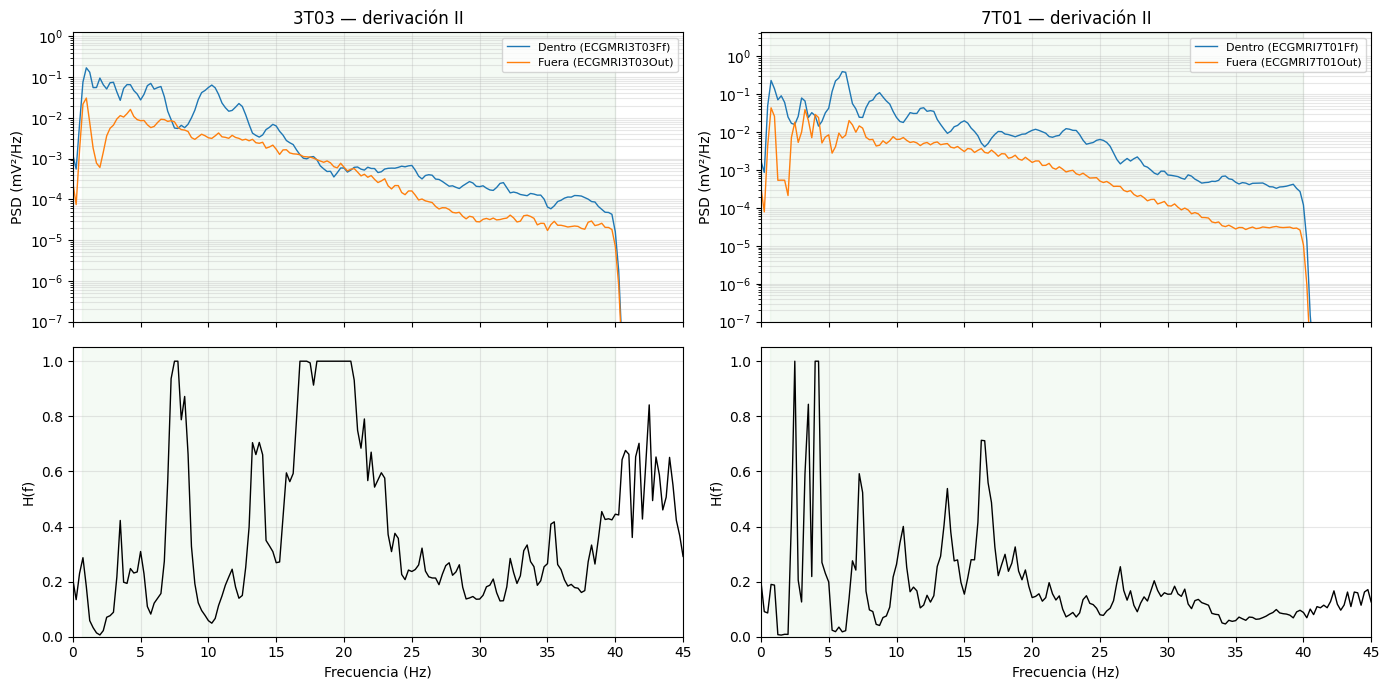

,Registro,"H media 0,67–10 Hz",H media 10–40 Hz
0,ECGMRI3T03Ff,0.29,0.40
1,ECGMRI7T01Ff,0.25,0.17


In [30]:
# Ejemplos: PSD dentro y fuera, y ganancia de Wiener (derivación II)
ejemplos_wiener = [("ECGMRI3T03Ff", "ECGMRI3T03Out"), ("ECGMRI7T01Ff", "ECGMRI7T01Out")]
BANDAS_H = {"0,67–10 Hz": (0.67, 10.0), "10–40 Hz": (10.0, 40.0)}

fig, ejes = plt.subplots(2, 2, figsize=(14, 7), sharex=True)
filas_h_ejemplo = []

for col, (nombre_dentro, nombre_fuera) in enumerate(ejemplos_wiener):
    w = wiener_derivacion(nombre_dentro, nombre_fuera, "II")

    ax = ejes[0, col]
    ax.semilogy(w["f"], w["PSD dentro"], lw=1, label=f"Dentro ({nombre_dentro})")
    ax.semilogy(w["f"], w["PSD fuera"], lw=1, label=f"Fuera ({nombre_fuera})")
    ax.set(title=f"{nombre_dentro[6:10]} — derivación II", ylabel="PSD (mV²/Hz)",
           ylim=(1e-7, None))
    ax.legend(fontsize=8)

    ax = ejes[1, col]
    ax.plot(w["f"], w["H"], color="k", lw=1)
    ax.set(ylabel="H(f)", xlabel="Frecuencia (Hz)", ylim=(0, 1.05))

    fila = {"Registro": nombre_dentro}
    for banda, (f1, f2) in BANDAS_H.items():
        fila[f"H media {banda}"] = w["H"][(w["f"] >= f1) & (w["f"] < f2)].mean()
    filas_h_ejemplo.append(fila)

for ax in ejes.flat:
    ax.set_xlim(0, 45)
    ax.axvspan(*BANDA_PASO_HZ, color="tab:green", alpha=0.05)
    ax.grid(alpha=0.3, which="both")

plt.tight_layout()
plt.show()

display(pd.DataFrame(filas_h_ejemplo).round(2))

En los dos ejemplos, la curva azul (dentro del resonador) está por encima de la naranja (fuera) en casi todas las frecuencias. Es decir, dentro del resonador hay más potencia en casi toda la banda, y el filtro interpreta ese exceso como interferencia.

Por eso la ganancia H(f) queda casi siempre muy por debajo de 1. H(f) indica qué fracción de la amplitud deja pasar el filtro en cada frecuencia: H = 1 deja pasar todo y H = 0,25 deja pasar solo un cuarto.

- **Entre 0,67 y 10 Hz**, donde están la onda T y el ST, la ganancia media es 0,29 en 3T03 y 0,25 en 7T01: el filtro deja pasar menos de un tercio de la amplitud en los dos casos.
- **Entre 10 y 40 Hz** hay una diferencia entre campos: en 3T03 la ganancia media es 0,40, pero en 7T01 baja a 0,17. A 7 T el exceso de potencia no se limita a las frecuencias bajas y aparece en toda la banda.

Como el ECG se repite en cada latido, su espectro no es una curva suave: tiene picos en múltiplos de la frecuencia cardíaca. Eso hace que la H(f) suba y baje tanto entre frecuencias cercanas. Por ejemplo, con 60 lpm (1 latido por segundo) hay picos en 1, 2, 3 Hz, etc. Dentro y fuera del resonador la frecuencia cardíaca no es la misma (en 7T01, 46,5 lpm dentro y 49,5 lpm fuera), así que los picos de una curva y de la otra caen en lugares un poco distintos. En las frecuencias donde la curva de afuera tiene un pico y la de adentro no, H sube de golpe; en las frecuencias donde pasa lo contrario, H baja de golpe.

Esto muestra que el primer supuesto del método (que el ECG tiene el mismo espectro dentro y fuera del resonador) no se cumple del todo: alcanza con que cambie la frecuencia cardíaca para que los espectros no coincidan.

Para ver si lo observado en estos dos ejemplos se repite en el resto, se aplica el filtro a todas las derivaciones de los 15 registros con referencia externa.

In [31]:
# Wiener en todos los registros con referencia externa
# Para cada derivación se resume la ganancia por bandas y se compara la
# varianza de la señal antes y después de Wiener con la de la referencia
# externa. Todas las medidas excluyen los bordes del FIR.

filas_wiener = []
for _, par in pares_wiener.iterrows():
    nombre_dentro, nombre_fuera = par["Registro"], par["Registro fuera"]
    derivaciones = wfdb.rdheader(str(carpeta_data / nombre_dentro)).sig_name

    for derivacion in derivaciones:
        w = wiener_derivacion(nombre_dentro, nombre_fuera, derivacion)
        borde = int(BORDE_S * w["fs"])
        varianza = {k: np.var(w[k][borde:-borde]) for k in ["Entrada", "Wiener", "Fuera"]}

        fila = {
            "Registro": nombre_dentro,
            "Campo (T)": par["Campo (T)"],
            "Derivación": derivacion,
            "Varianza entrada / fuera": varianza["Entrada"] / varianza["Fuera"],
            "Varianza Wiener / fuera": varianza["Wiener"] / varianza["Fuera"],
        }
        for banda, (f1, f2) in BANDAS_H.items():
            fila[f"H media {banda}"] = w["H"][(w["f"] >= f1) & (w["f"] < f2)].mean()
        filas_wiener.append(fila)

resultados_wiener = pd.DataFrame(filas_wiener)
print(f"Combinaciones registro–derivación: {len(resultados_wiener)}")
display(resultados_wiener.groupby("Campo (T)")
        .median(numeric_only=True).round(2)
        .assign(**{"n": resultados_wiener.groupby("Campo (T)").size()}))
print("Todas las combinaciones — mediana [Q25; Q75]:")
display(resultados_wiener.drop(columns="Campo (T)")
        .describe(percentiles=[0.25, 0.5, 0.75])
        .loc[["25%", "50%", "75%"]].round(2))

Combinaciones registro–derivación: 180


,Varianza entrada / fuera,Varianza Wiener / fuera,"H media 0,67–10 Hz",H media 10–40 Hz,n
Campo (T),,,,,
1,5.14,0.50,0.37,0.70,24
3,5.16,0.40,0.28,0.70,60
7,15.37,0.21,0.14,0.34,96


Todas las combinaciones — mediana [Q25; Q75]:


,Varianza entrada / fuera,Varianza Wiener / fuera,"H media 0,67–10 Hz",H media 10–40 Hz
25%,4.78,0.16,0.09,0.26
50%,10.77,0.30,0.22,0.56
75%,23.66,0.44,0.35,0.71


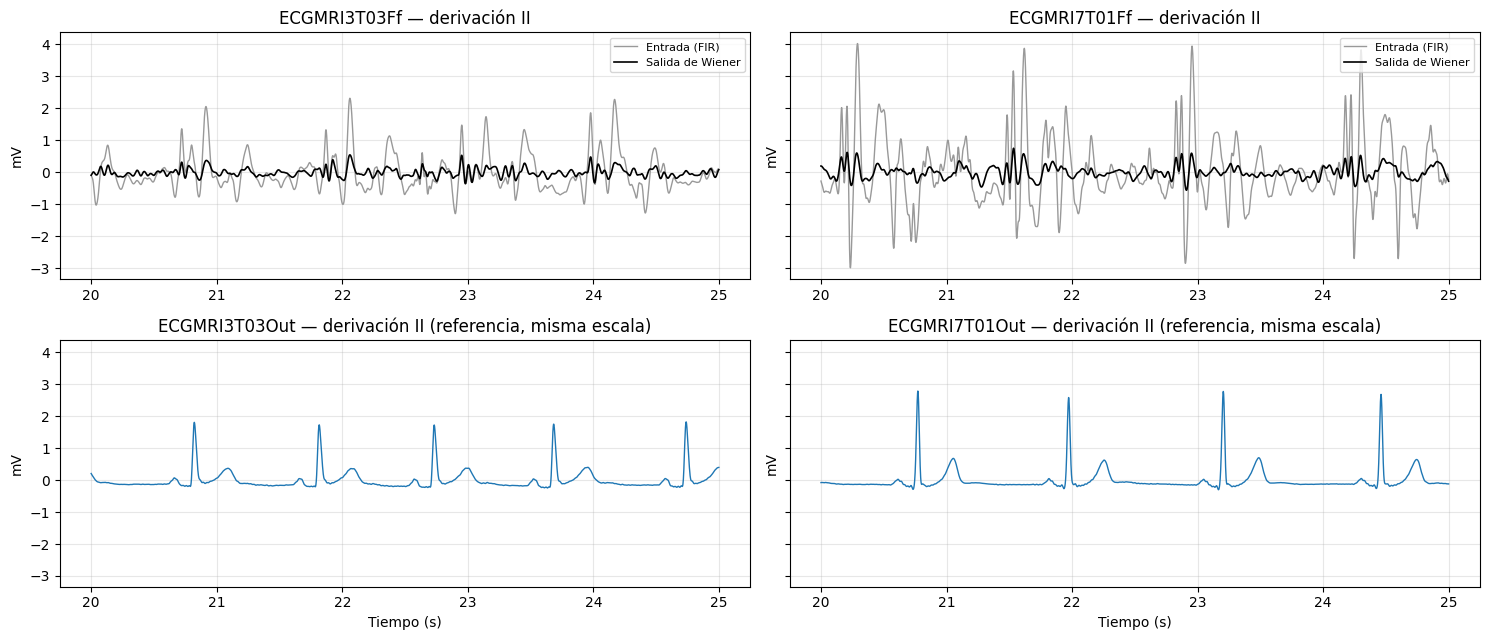

In [35]:

# Ejemplos en el tiempo: entrada (FIR), salida de Wiener y referencia externa
INICIO_W_S, DURACION_W_S = 20.0, 5.0

fig, ejes = plt.subplots(2, 2, figsize=(15, 6.5), sharey=True)   # misma escala en los 4 paneles

for col, (nombre_dentro, nombre_fuera) in enumerate(ejemplos_wiener):
    w = wiener_derivacion(nombre_dentro, nombre_fuera, "II")
    i0 = int(INICIO_W_S * w["fs"])
    i1 = int((INICIO_W_S + DURACION_W_S) * w["fs"])
    t = np.arange(i0, i1) / w["fs"]

    ax = ejes[0, col]
    ax.plot(t, w["Entrada"][i0:i1], color="0.6", lw=1, label="Entrada (FIR)")
    ax.plot(t, w["Wiener"][i0:i1], color="k", lw=1.2, label="Salida de Wiener")
    ax.set(title=f"{nombre_dentro} — derivación II", ylabel="mV")
    ax.legend(fontsize=8, loc="upper right")

    ax = ejes[1, col]
    ax.plot(t, w["Fuera"][i0:i1], color="tab:blue", lw=1)
    ax.set(title=f"{nombre_fuera} — derivación II (referencia, misma escala)",
           ylabel="mV", xlabel="Tiempo (s)")

for ax in ejes.flat:
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

### Resultado del filtro de Wiener en frecuencia

**El filtro atenúa más de lo necesario.** Antes del filtro, la señal dentro del resonador tiene, en mediana, 10,8 veces la varianza de la referencia externa: le sobra potencia por el MHD. Lo esperable de un buen filtro sería acercar ese cociente a 1, es decir, dejar la señal con una potencia parecida a la de afuera. Después de Wiener, en cambio, el cociente queda en 0,30: la salida tiene menos de un tercio de la potencia de la referencia. El filtro no solo sacó el exceso, sino que también se llevó parte del ECG.

Esto pasa porque el filtro busca la salida con el menor error cuadrático medio posible. Cuando en una frecuencia la interferencia es mucho mayor que la señal, la opción de menor error es atenuar esa frecuencia casi por completo, aunque eso también elimine la parte del ECG que había en ella. Como dentro del resonador sobra potencia en casi todas las frecuencias, el filtro atenúa casi todo.

**El efecto aumenta con el campo magnético.** La ganancia media entre 0,67 y 10 Hz es 0,37 en 1 T, 0,28 en 3 T y 0,14 en 7 T. Entre 10 y 40 Hz es 0,70 en 1 T y 3 T y baja a 0,34 en 7 T. A mayor campo, mayor MHD, y el filtro atenúa más.

**En la figura de los ejemplos** se ve el mismo resultado sobre la señal: la salida de Wiener es mucho más chica que la referencia de afuera, en la misma escala, y ya no tiene la forma P-QRS-T. Se siguen viendo picos que se repiten con cada latido, pero no queda claro cuáles corresponden a los QRS.

Esto coincide con lo que reportaron Krug et al. (2012): Wiener tiene una utilidad limitada para este problema. Acá se observa en una versión que no necesita conocer la ubicación de los latidos.

Mirando la figura no se puede saber si la salida de Wiener facilita o dificulta la detección del QRS respecto de la señal con FIR. **Por eso, en la sección siguiente se aplica el detector a las dos versiones de la señal y se comparan los resultados con la referencia.**